## Setup

In [1]:
# If anything is missing, uncomment:
# %pip install pandas numpy scipy statsmodels matplotlib


In [2]:
from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
from scipy import stats, signal
from scipy.optimize import minimize_scalar
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.stattools import adfuller, kpss, grangercausalitytests, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.bbox"] = "tight"
pd.set_option("display.float_format", lambda x: f"{x:.6f}")


## Config — set Paths

In [3]:
import os

# project root 
THESIS_DATA_ROOT = Path(os.environ.get("THESIS_DATA_ROOT", "./thesis_data")).resolve()
ROOT = THESIS_DATA_ROOT
ROOT.mkdir(parents=True, exist_ok=True)

INDICES_PATH = THESIS_DATA_ROOT / "Phase 3" / "full_period_US_phase3_20260602_014115" / "US_full_period_phase3_daily_indices.csv"
SUMMARY_PATH = THESIS_DATA_ROOT / "Phase 3" / "full_period_US_phase3_20260602_014115" / "US_full_period_phase3_summary.csv"         

## Load data

### Index 

In [4]:
import os
from pathlib import Path

# project root 
THESIS_DATA_ROOT = Path(os.environ.get("THESIS_DATA_ROOT", "./thesis_data")).resolve()
ROOT = THESIS_DATA_ROOT
ROOT.mkdir(parents=True, exist_ok=True)

# Submission Ready root 
SUBMISSION_ROOT = Path(os.environ.get(
    "SUBMISSION_ROOT", str(Path.home() / "Desktop" / "PCRA Index Thesis")
)).resolve()


INDICES_PATH = (SUBMISSION_ROOT / "Actual Run Data" / "Phase 3 - Index"
                 / "US_full_period_phase3_daily_indices.csv")
SUMMARY_PATH = (SUBMISSION_ROOT / "Actual Run Data" / "Phase 3 - Index"
                 / "US_full_period_phase3_summary.csv")


STAGE_A_DIRS = [
    SUBMISSION_ROOT / "Actual Run Data" / "Phase 1 - Articles Kept vs Rejected"
    / "Stage A" / "Full Data",
]

StageB_PATH = (SUBMISSION_ROOT / "Actual Run Data" / "Phase 1 - Articles Kept vs Rejected")

figdir = SUBMISSION_ROOT / "Visuals" / "Index-Level"
figdir.mkdir(parents=True, exist_ok=True)

print(f"SUBMISSION_ROOT: {SUBMISSION_ROOT}  {'✓' if SUBMISSION_ROOT.exists() else '✗ NOT FOUND'}")
print(f"  Indices: {INDICES_PATH}  {'✓' if INDICES_PATH.exists() else '✗ NOT FOUND'}")
print(f"  Summary: {SUMMARY_PATH}  {'✓' if SUMMARY_PATH.exists() else '✗ NOT FOUND'}")
print(f"  Statistical Properties: {StageB_PATH}  {'✓' if SUMMARY_PATH.exists() else '✗ NOT FOUND'}")
print(f"  Figures: {figdir}  {'✓ created/exists' if figdir.exists() else '✗ FAILED'}")


SUBMISSION_ROOT: /Users/adam/Desktop/PCRA Index Thesis  ✓
  Indices: /Users/adam/Desktop/PCRA Index Thesis/Actual Run Data/Phase 3 - Index/US_full_period_phase3_daily_indices.csv  ✓
  Summary: /Users/adam/Desktop/PCRA Index Thesis/Actual Run Data/Phase 3 - Index/US_full_period_phase3_summary.csv  ✓
  Statistical Properties: /Users/adam/Desktop/PCRA Index Thesis/Actual Run Data/Phase 1 - Articles Kept vs Rejected  ✓
  Figures: /Users/adam/Desktop/PCRA Index Thesis/Visuals/Index-Level  ✓ created/exists


### Derived financial-data paths

In [5]:
from pathlib import Path

# Derived paths 
EMDAT_DIR = SUBMISSION_ROOT / "Financial Data" / "Disaster"
EPU_DIR   = SUBMISSION_ROOT / "Financial Data" / "Other Indices"

# Country name --> ISO code for EM-DAT filenames
EMDAT_FILES = {
    "US": EMDAT_DIR / "EMDAT_US.xlsx",
}

# Verify expected paths exist
print(f"SUBMISSION_ROOT: {SUBMISSION_ROOT}  {'✓' if SUBMISSION_ROOT.exists() else '✗ NOT FOUND'}")
print(f"  EM-DAT:    {EMDAT_DIR}  {'✓' if EMDAT_DIR.exists() else '✗ NOT FOUND'}")
print(f"  Other Idx: {EPU_DIR}  {'✓' if EPU_DIR.exists() else '✗ NOT FOUND'}")

SUBMISSION_ROOT: /Users/adam/Desktop/PCRA Index Thesis  ✓
  EM-DAT:    /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Disaster  ✓
  Other Idx: /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Other Indices  ✓


In [6]:
# path

EPU_PATH = EPU_DIR / "All_Daily_Policy_Data.csv"

print(f"  EPU path: {EPU_PATH}")
print(f"  Exists  : {'✓' if EPU_PATH.exists() else '✗ NOT FOUND'}")

if not EPU_PATH.exists():
    raise FileNotFoundError(
        f"EPU file not found at {EPU_PATH}\n"
        f"Files currently in Other Indices folder:\n"
        + "\n".join(f"  {f.name}" for f in EPU_DIR.iterdir())
        if EPU_DIR.exists() else
        f"EPU file not found at {EPU_PATH}\nOther Indices folder itself doesn't exist: {EPU_DIR}"
    )



epu_raw = pd.read_csv(EPU_PATH)
print(f"\n✓ Loaded EPU: {len(epu_raw):,} rows")
print(f"  Columns: {list(epu_raw.columns)}")

# Build date from year  month  day 

epu_raw["date"] = pd.to_datetime({
    "year":  epu_raw["year"].astype(int),
    "month": epu_raw["month"].astype(int),
    "day":   epu_raw["day"].astype(int),
}, errors="coerce")

#  Clean & filter 

epu_df = epu_raw[["date", "daily_policy_index"]].copy()
epu_df.columns = ["date", "epu"]
epu_df["epu"] = pd.to_numeric(epu_df["epu"], errors="coerce")
epu_df = epu_df.dropna(subset=["date", "epu"])

epu_df = epu_df[
    (epu_df["date"] >= "2008-01-01") &
    (epu_df["date"] <= "2025-12-31")
].sort_values("date").reset_index(drop=True)

# Summary 

print(f"\n✓ epu_df ready")
print(f"  Observations : {len(epu_df):,}")
print(f"  Date range   : {epu_df['date'].min().date()} "
      f"→ {epu_df['date'].max().date()}")
print(f"  Mean EPU     : {epu_df['epu'].mean():.2f}")
print(f"  Max EPU      : {epu_df['epu'].max():.2f}")

display(epu_df.head())

  EPU path: /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Other Indices/All_Daily_Policy_Data.csv
  Exists  : ✓

✓ Loaded EPU: 15,125 rows
  Columns: ['day', 'month', 'year', 'daily_policy_index']

✓ epu_df ready
  Observations : 6,575
  Date range   : 2008-01-01 → 2025-12-31
  Mean EPU     : 144.66
  Max EPU      : 1026.38


,date,epu
0,2008-01-01,232.870000
1,2008-01-02,83.140000
2,2008-01-03,189.340000
3,2008-01-04,103.240000
4,2008-01-05,281.750000


In [7]:
#  Load US EM-DAT file 
emdat_raw = pd.read_excel(EMDAT_FILES["US"])
print(f"\n✓ Loaded EM-DAT US: {len(emdat_raw):,} rows")
print(f"  Columns: {list(emdat_raw.columns)}")

#  Identify date column 

if "Start Year" in emdat_raw.columns:
    emdat_raw["event_date"] = pd.to_datetime({
        "year":  emdat_raw["Start Year"].fillna(0).astype(int),
        "month": emdat_raw["Start Month"].fillna(1).astype(int),
        "day":   emdat_raw["Start Day"].fillna(1).astype(int),
    }, errors="coerce")
elif "Disaster Date" in emdat_raw.columns:
    emdat_raw["event_date"] = pd.to_datetime(
        emdat_raw["Disaster Date"], errors="coerce")
elif "Event Date" in emdat_raw.columns:
    emdat_raw["event_date"] = pd.to_datetime(
        emdat_raw["Event Date"], errors="coerce")
else:
    raise RuntimeError(
        f"Cannot find a date column in EM-DAT. "
        f"Available columns: {list(emdat_raw.columns)}")

#  Filter to sample period & drop undated rows 

emdat_us = emdat_raw.dropna(subset=["event_date"]).copy()
emdat_us = emdat_us[
    (emdat_us["event_date"] >= "2008-01-01") &
    (emdat_us["event_date"] <= "2025-12-31")
].reset_index(drop=True)

print(f"  After date filter (2008–2025): {len(emdat_us):,} events")


✓ Loaded EM-DAT US: 417 rows
  Columns: ['DisNo.', 'Historic', 'Classification Key', 'Disaster Group', 'Disaster Subgroup', 'Disaster Type', 'Disaster Subtype', 'External IDs', 'Event Name', 'ISO', 'Country', 'Subregion', 'Region', 'Location', 'Origin', 'Associated Types', 'OFDA/BHA Response', 'Appeal', 'Declaration', "AID Contribution ('000 US$)", 'Magnitude', 'Magnitude Scale', 'Latitude', 'Longitude', 'River Basin', 'Start Year', 'Start Month', 'Start Day', 'End Year', 'End Month', 'End Day', 'Total Deaths', 'No. Injured', 'No. Affected', 'No. Homeless', 'Total Affected', "Reconstruction Costs ('000 US$)", "Reconstruction Costs, Adjusted ('000 US$)", "Insured Damage ('000 US$)", "Insured Damage, Adjusted ('000 US$)", "Total Damage ('000 US$)", "Total Damage, Adjusted ('000 US$)", 'CPI', 'Admin Units', 'GADM Admin Units', 'Entry Date', 'Last Update']
  After date filter (2008–2025): 417 events


In [8]:
# EM-DAT EVENT LOADING — US

import pandas as pd
import numpy as np
from pathlib import Path

# EM-DAT file 
EMDAT_FILES = {
    "US": EMDAT_DIR / "EMDAT_US.xlsx",
}

print(f"  EM-DAT US path: {EMDAT_FILES['US']}")
print(f"  Exists        : {'✓' if EMDAT_FILES['US'].exists() else '✗ NOT FOUND'}")

if not EMDAT_FILES["US"].exists():
    raise FileNotFoundError(
        f"EM-DAT file not found at {EMDAT_FILES['US']}\n"
        f"Files currently in EM-DAT folder:\n"
        + ("\n".join(f"  {f.name}" for f in EMDAT_DIR.iterdir())
           if EMDAT_DIR.exists() else f"  (folder itself doesn't exist: {EMDAT_DIR})")
    )

# Load US EM-DAT file 

emdat_raw = pd.read_excel(EMDAT_FILES["US"])
print(f"\n✓ Loaded EM-DAT US: {len(emdat_raw):,} rows")
print(f"  Columns: {list(emdat_raw.columns)}")

# Identify date column 

if "Start Year" in emdat_raw.columns:
    emdat_raw["event_date"] = pd.to_datetime({
        "year":  emdat_raw["Start Year"].fillna(0).astype(int),
        "month": emdat_raw["Start Month"].fillna(1).astype(int),
        "day":   emdat_raw["Start Day"].fillna(1).astype(int),
    }, errors="coerce")
elif "Disaster Date" in emdat_raw.columns:
    emdat_raw["event_date"] = pd.to_datetime(
        emdat_raw["Disaster Date"], errors="coerce")
elif "Event Date" in emdat_raw.columns:
    emdat_raw["event_date"] = pd.to_datetime(
        emdat_raw["Event Date"], errors="coerce")
else:
    raise RuntimeError(
        f"Cannot find a date column in EM-DAT. "
        f"Available columns: {list(emdat_raw.columns)}")

#  Filter to sample period & drop undated rows 

emdat_us = emdat_raw.dropna(subset=["event_date"]).copy()
emdat_us = emdat_us[
    (emdat_us["event_date"] >= "2008-01-01") &
    (emdat_us["event_date"] <= "2025-12-31")
].reset_index(drop=True)

print(f"  After date filter (2008–2025): {len(emdat_us):,} events")

# Build emdat_dates

emdat_dates = pd.to_datetime(
    emdat_us["event_date"].dropna().values,
    errors="coerce"
)
emdat_dates = emdat_dates[~pd.isnull(emdat_dates)]

print(f"  emdat_dates ready : {len(emdat_dates):,} dates")

# Build EMDAT_EVENTS

_desc_col = next(
    (c for c in ["Disaster Type", "Event Name", "Disaster Subtype", "Type"]
     if c in emdat_us.columns), None)

_type_col = next(
    (c for c in ["Disaster Subtype", "Disaster Type", "Event Type"]
     if c in emdat_us.columns), None)

_chronic_terms = [
    "drought", "sea level", "heat stress", "extreme temperature",
    "cold wave", "heat wave", "wildfire", "land fire"
]

def _classify_type(row):
    if _type_col is None:
        return "acute"
    val = str(row[_type_col]).lower()
    return "chronic" if any(t in val for t in _chronic_terms) else "acute"

emdat_us["etype"] = emdat_us.apply(_classify_type, axis=1)

if _desc_col:
    EMDAT_EVENTS = list(zip(
        emdat_us["event_date"].dt.strftime("%Y-%m-%d"),
        emdat_us[_desc_col].fillna("Unknown"),
        emdat_us["etype"]
    ))
else:
    EMDAT_EVENTS = list(zip(
        emdat_us["event_date"].dt.strftime("%Y-%m-%d"),
        ["Event"] * len(emdat_us),
        emdat_us["etype"]
    ))

print(f"  EMDAT_EVENTS ready: {len(EMDAT_EVENTS):,} entries "
      f"({emdat_us['etype'].eq('acute').sum():,} acute, "
      f"{emdat_us['etype'].eq('chronic').sum():,} chronic)")

  EM-DAT US path: /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Disaster/EMDAT_US.xlsx
  Exists        : ✓

✓ Loaded EM-DAT US: 417 rows
  Columns: ['DisNo.', 'Historic', 'Classification Key', 'Disaster Group', 'Disaster Subgroup', 'Disaster Type', 'Disaster Subtype', 'External IDs', 'Event Name', 'ISO', 'Country', 'Subregion', 'Region', 'Location', 'Origin', 'Associated Types', 'OFDA/BHA Response', 'Appeal', 'Declaration', "AID Contribution ('000 US$)", 'Magnitude', 'Magnitude Scale', 'Latitude', 'Longitude', 'River Basin', 'Start Year', 'Start Month', 'Start Day', 'End Year', 'End Month', 'End Day', 'Total Deaths', 'No. Injured', 'No. Affected', 'No. Homeless', 'Total Affected', "Reconstruction Costs ('000 US$)", "Reconstruction Costs, Adjusted ('000 US$)", "Insured Damage ('000 US$)", "Insured Damage, Adjusted ('000 US$)", "Total Damage ('000 US$)", "Total Damage, Adjusted ('000 US$)", 'CPI', 'Admin Units', 'GADM Admin Units', 'Entry Date', 'Last Update']
  After date filter 

## Helpers

In [9]:
@dataclass
class CheckResult:
    name: str
    passed: bool | None
    value: str
    note: str = ""

    def show(self):
        if self.passed is None:
            tag = "[ INFO ]"
        elif self.passed:
            tag = "[ PASS ]"
        else:
            tag = "[ FAIL ]"
        print(f"{tag}  {self.name:55s}  {self.value}")
        if self.note:
            print(f"          note: {self.note}")


def ewma(x: np.ndarray, lam: float, init: float | None = None) -> np.ndarray:
    """SSI_t = lam*SSI_{t-1} + (1-lam)*S_t (proposal Phase 3)."""
    out = np.empty_like(x, dtype=float)
    out[0] = init if init is not None else x[0]
    for i in range(1, len(x)):
        out[i] = lam * out[i - 1] + (1.0 - lam) * x[i]
    return out


def kpss_safe(series, regression="c"):
    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        stat, p, *_ = kpss(series, regression=regression, nlags="auto")
    return stat, p


def hl_to_lambda(hl: int) -> float:
    """Half-life (business days) -> EWMA lambda. lambda^h = 1/2."""
    return float(2.0 ** (-1.0 / hl))


def distance_correlation(x: np.ndarray, y: np.ndarray) -> float:
    """Szekely-Rizzo-Bakirov distance correlation. O(n^2)."""
    x = np.asarray(x, dtype=float).reshape(-1)
    y = np.asarray(y, dtype=float).reshape(-1)
    a = np.abs(x[:, None] - x[None, :])
    b = np.abs(y[:, None] - y[None, :])
    A = a - a.mean(0) - a.mean(1)[:, None] + a.mean()
    B = b - b.mean(0) - b.mean(1)[:, None] + b.mean()
    dcov2 = (A * B).mean()
    dvar_x = (A * A).mean()
    dvar_y = (B * B).mean()
    if dvar_x <= 0 or dvar_y <= 0:
        return 0.0
    return float(np.sqrt(max(dcov2, 0.0)) / np.sqrt(np.sqrt(dvar_x * dvar_y)))

results: list[CheckResult] = []

In [10]:
def ewma(x, lam, init=None):
    out = np.empty_like(x, dtype=float)
    out[0] = init if init is not None else x[0]
    for i in range(1, len(x)):
        out[i] = lam * out[i - 1] + (1.0 - lam) * x[i]
    return out


def kpss_safe(series, regression="c"):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        stat, p, *_ = kpss(series, regression=regression, nlags="auto")
    return stat, p


def variance_ratio(x, q):
    """Lo-MacKinlay variance ratio test. VR(q) and asymptotic z-stat."""
    n = len(x)
    mu = (x[-1] - x[0]) / n
    # sigma_1^2
    s1 = np.sum((x[1:] - x[:-1] - mu) ** 2) / (n - 1)
    # sigma_q^2
    diffs_q = x[q:] - x[:-q] - q * mu
    sq = np.sum(diffs_q ** 2) / (n - q)
    vr = sq / (q * s1) if s1 > 0 else np.nan
    # Asymptotic z under homoscedasticity
    z = (vr - 1) / np.sqrt(2 * (q - 1) / (3 * q * n)) if not np.isnan(vr) else np.nan
    return float(vr), float(z)

In [11]:
#  Load combined daily indices 
df = pd.read_csv(INDICES_PATH)
df["date"] = pd.to_datetime(df["date"])

print(f"  Loaded : {len(df):,} rows")
print(f"  Columns: {list(df.columns)}")
print(f"  Range  : {df['date'].min().date()} → {df['date'].max().date()}")

#  Rename DSP --> CSP 
df = df.rename(columns={"DSP": "CSP"})

  Loaded : 4,697 rows
  Columns: ['date', 'country', 'S_daily_raw', 'S_daily', 'SSI', 'DSP']
  Range  : 2008-01-01 → 2025-12-31


# Statistical Properties

## Construction & Basic Properties

### SSI construction

In [12]:
from scipy.optimize import minimize_scalar

TARGET_LAMBDA = 0.977

s        = df["S_daily_raw"].fillna(0.0).values
ssi_data = df["SSI"].values

#  reconstruct at proposal lambda 
ssi_hat  = ewma(s, TARGET_LAMBDA, init=ssi_data[0])
err      = np.abs(ssi_data - ssi_hat)
max_err  = float(np.nanmax(err))
mean_err = float(np.nanmean(err))

#  best-fit lambda via bounded scalar optimisation 
def _loss(l):
    rec = ewma(s, l, init=ssi_data[0])
    return float(np.nansum((rec - ssi_data) ** 2))

best_lambda = float(minimize_scalar(_loss, bounds=(0.5, 0.9999), method="bounded").x)

r = CheckResult(
    "SSI = EWMA(S_raw, lambda=0.977)",
    max_err < 1e-3,
    f"max|err|={max_err:.2e}, mean|err|={mean_err:.2e}",
    f"best-fit lambda = {best_lambda:.6f} (target {TARGET_LAMBDA})",
)
results.append(r); r.show()

[ PASS ]  SSI = EWMA(S_raw, lambda=0.977)                          max|err|=4.15e-05, mean|err|=3.64e-06
          note: best-fit lambda = 0.977159 (target 0.977)


### CSP Distribution

In [13]:
#   Mean and std checks 
csp = df["CSP"].dropna().values
mu  = float(csp.mean())
sd  = float(csp.std(ddof=1))

for r in [
    CheckResult("CSP mean ~ 0",
                abs(mu) < 0.1,
                f"mean = {mu:+.4f}",
                "proposal: zero-mean after AR residualisation"),
    CheckResult("CSP std ~ 1",
                0.85 < sd < 1.15,
                f"std  = {sd:.4f}",
                "proposal: rolling-252 standardisation; short trials drift"),
]:
    results.append(r); r.show()

[ PASS ]  CSP mean ~ 0                                             mean = -0.0028
          note: proposal: zero-mean after AR residualisation
[ PASS ]  CSP std ~ 1                                              std  = 0.9956
          note: proposal: rolling-252 standardisation; short trials drift


### Orthogonality checks

In [14]:
#  Orthogonality: linear and distance correlation 
tmp  = pd.DataFrame({"CSP": df["CSP"], "SSI_lag": df["SSI"].shift(1)}).dropna()
rho  = float(tmp["CSP"].corr(tmp["SSI_lag"]))
dcor = distance_correlation(tmp["CSP"].values, tmp["SSI_lag"].values)

for r in [
    CheckResult("corr(CSP_t, SSI_{t-1})",
                abs(rho) < 0.1,
                f"rho = {rho:+.4f}",
                "proposal: approximately orthogonal by construction"),
    CheckResult("dcor(CSP_t, SSI_{t-1})",
                dcor < 0.15,
                f"dcor = {dcor:.4f}",
                "distance correlation"),
]:
    results.append(r); r.show()

[ PASS ]  corr(CSP_t, SSI_{t-1})                                   rho = -0.0589
          note: proposal: approximately orthogonal by construction
[ FAIL ]  dcor(CSP_t, SSI_{t-1})                                   dcor = 0.1882
          note: distance correlation


## Distributional & Persistence Diagnostics

###  Stationarity

In [15]:
import warnings
from statsmodels.tsa.stattools import adfuller, kpss

def kpss_safe(x, regression="c"):
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            stat, p, lags, crit = kpss(x, regression=regression, nlags="auto")
        return stat, p
    except Exception:
        return np.nan, np.nan

print("── Stationarity tests ──\n")
for col, expect_stationary in [("SSI", False), ("CSP", True)]:
    x        = df[col].dropna().values
    _, adf_p, *_ = adfuller(x, autolag="AIC")
    _, kpss_p    = kpss_safe(x, regression="c")
    adf_stat     = adf_p < 0.05
    kpss_stat    = kpss_p > 0.05
    agreed       = adf_stat and kpss_stat
    verdict      = ("stationary"     if agreed
                    else "non-stationary" if (not adf_stat and not kpss_stat)
                    else "ambiguous")
    ok = agreed if expect_stationary else (not adf_stat or not kpss_stat)
    r  = CheckResult(
        f" Stationarity of {col}",
        ok,
        f"ADF p={adf_p:.3f}, KPSS p={kpss_p:.3f}  ->  {verdict}",
        f"expected: {'stationary' if expect_stationary else 'persistent / not-stationary'}")
    results.append(r); r.show()

── Stationarity tests ──

[ PASS ]   Stationarity of SSI                                     ADF p=0.001, KPSS p=0.010  ->  ambiguous
          note: expected: persistent / not-stationary
[ PASS ]   Stationarity of CSP                                     ADF p=0.000, KPSS p=0.100  ->  stationary
          note: expected: stationary


### Whiteness

In [16]:
from statsmodels.stats.diagnostic import acorr_ljungbox

dsp = df["CSP"].dropna().values

rho1 = float(np.corrcoef(dsp[:-1], dsp[1:])[0, 1])
r = CheckResult(
    "A3a. SP autocorrelation rho(1)",
    abs(rho1) < 0.10,
    f"rho(1) = {rho1:+.4f}",
    "proposal: AR residual should give rho(1) near 0")
results.append(r); r.show()

lb = acorr_ljungbox(dsp, lags=[1, 5, 10], return_df=True)
for lag in [1, 5, 10]:
    p = float(lb.loc[lag, "lb_pvalue"])
    Q = float(lb.loc[lag, "lb_stat"])
    r = CheckResult(
        f"Ljung-Box(lag={lag}) on CSP",
        p > 0.05,
        f"Q={Q:.2f}, p={p:.4f}",
        "H0: no autocorrelation up to lag; pass = fail to reject")
    results.append(r); r.show()

[ PASS ]  A3a. SP autocorrelation rho(1)                           rho(1) = +0.0373
          note: proposal: AR residual should give rho(1) near 0
[ FAIL ]  Ljung-Box(lag=1) on CSP                                  Q=6.20, p=0.0128
          note: H0: no autocorrelation up to lag; pass = fail to reject
[ PASS ]  Ljung-Box(lag=5) on CSP                                  Q=10.64, p=0.0591
          note: H0: no autocorrelation up to lag; pass = fail to reject
[ PASS ]  Ljung-Box(lag=10) on CSP                                 Q=15.57, p=0.1127
          note: H0: no autocorrelation up to lag; pass = fail to reject


### ARCH-LM (volatility clustering)

In [17]:
from statsmodels.stats.diagnostic import het_arch

for q in [1, 5, 10]:
    try:
        lm_stat, lm_p, fstat, fp = het_arch(dsp, nlags=q)
        sig = ("***" if lm_p < 0.01 else
               "**"  if lm_p < 0.05 else
               "*"   if lm_p < 0.10 else "")
        print(f"ARCH({q:2d}):  LM stat={lm_stat:8.2f},  p={lm_p:.4f} {sig}")
    except Exception as e:
        print(f"ARCH({q:2d}):  could not compute — {e}")

print("\nS daily raw")
s_raw = df["S_daily_raw"].dropna().values
for q in [1, 5]:
    try:
        lm_stat, lm_p, _, _ = het_arch(s_raw, nlags=q)
        sig = ("***" if lm_p < 0.01 else
               "**"  if lm_p < 0.05 else "")
        print(f"ARCH({q}):  LM stat={lm_stat:.2f},  p={lm_p:.4f} {sig}")
    except Exception as e:
        print(f"ARCH({q}):  {e}")

print("\nInterpretation: significant = volatility clustering in shocks.")

ARCH( 1):  LM stat=    0.00,  p=0.9710 
ARCH( 5):  LM stat=    0.61,  p=0.9877 
ARCH(10):  LM stat=    5.74,  p=0.8368 

S daily raw
ARCH(1):  LM stat=0.01,  p=0.9345 
ARCH(5):  LM stat=0.20,  p=0.9992 

Interpretation: significant = volatility clustering in shocks.


### Distribution statistics

In [18]:
from scipy import stats

for col in ["S_daily_raw", "SSI", "CSP"]:
    x             = df[col].dropna().values
    sk            = float(stats.skew(x))
    kt            = float(stats.kurtosis(x))
    jb_stat, jb_p = stats.jarque_bera(x)
    r = CheckResult(
        f"Distribution of {col}",
        None,
        f"skew={sk:+.2f}, ex.kurt={kt:+.2f}, JB p={jb_p:.4f}",
        "JB H0: normality; news shocks typically reject (heavy tails)")
    results.append(r); r.show()

[ INFO ]  Distribution of S_daily_raw                              skew=+10.91, ex.kurt=+212.75, JB p=0.0000
          note: JB H0: normality; news shocks typically reject (heavy tails)
[ INFO ]  Distribution of SSI                                      skew=-0.01, ex.kurt=-0.44, JB p=0.0000
          note: JB H0: normality; news shocks typically reject (heavy tails)
[ INFO ]  Distribution of CSP                                      skew=+6.16, ex.kurt=+59.38, JB p=0.0000
          note: JB H0: normality; news shocks typically reject (heavy tails)


## CSP Dynamics & Robustness

### Spectral density of CSP

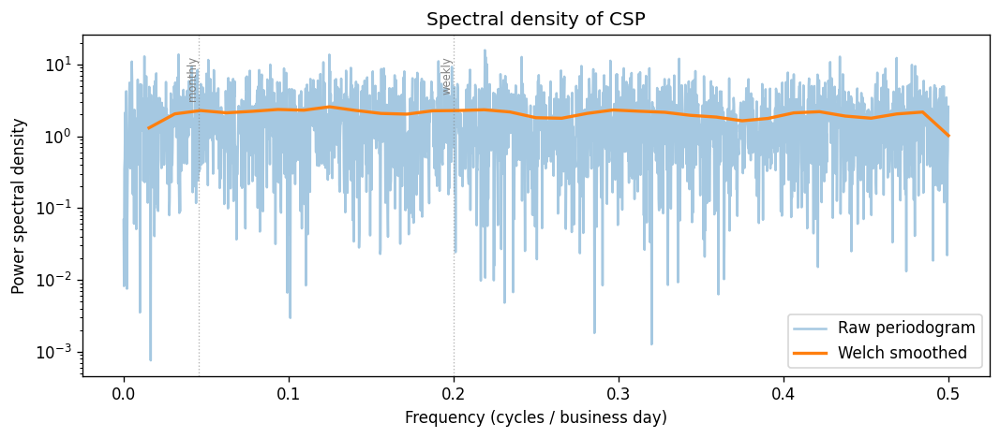

In [19]:
from scipy import signal

freqs,   psd   = signal.periodogram(dsp, fs=1.0, detrend="linear")
freqs_w, psd_w = signal.welch(
    dsp, fs=1.0,
    nperseg=min(64, len(dsp) // 2),
    detrend="linear")

fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogy(freqs[1:], psd[1:],   alpha=0.4, label="Raw periodogram")
ax.semilogy(freqs_w[1:], psd_w[1:], lw=2,   label="Welch smoothed")
ax.set_xlabel("Frequency (cycles / business day)")
ax.set_ylabel("Power spectral density")
ax.set_title("Spectral density of CSP")
ax.legend()
for freq_mark, lbl in [(1/5, "weekly"), (1/22, "monthly")]:
    ax.axvline(freq_mark, color="grey", ls=":", lw=0.8, alpha=0.6)
    ax.text(freq_mark, ax.get_ylim()[1] * 0.5, lbl,
            fontsize=7, rotation=90, va="top", ha="right", color="grey")
fig.tight_layout()
fig.savefig(figdir / "g9_spectral_dsp.png", dpi=130)
plt.show()

In [20]:
cumulative_power    = np.cumsum(psd[1:]) / np.sum(psd[1:])
pct_below_weekly    = (float(cumulative_power[freqs[1:] <= 1/5][-1])
                       if np.any(freqs[1:] <= 1/5) else 0)
print(f"Power below weekly frequency: {pct_below_weekly:.1%}")
print(f"(White noise expected ~{(1/5)/0.5:.0%}; higher = residual persistence)")

Power below weekly frequency: 42.6%
(White noise expected ~40%; higher = residual persistence)


### Rolling CSP statistics

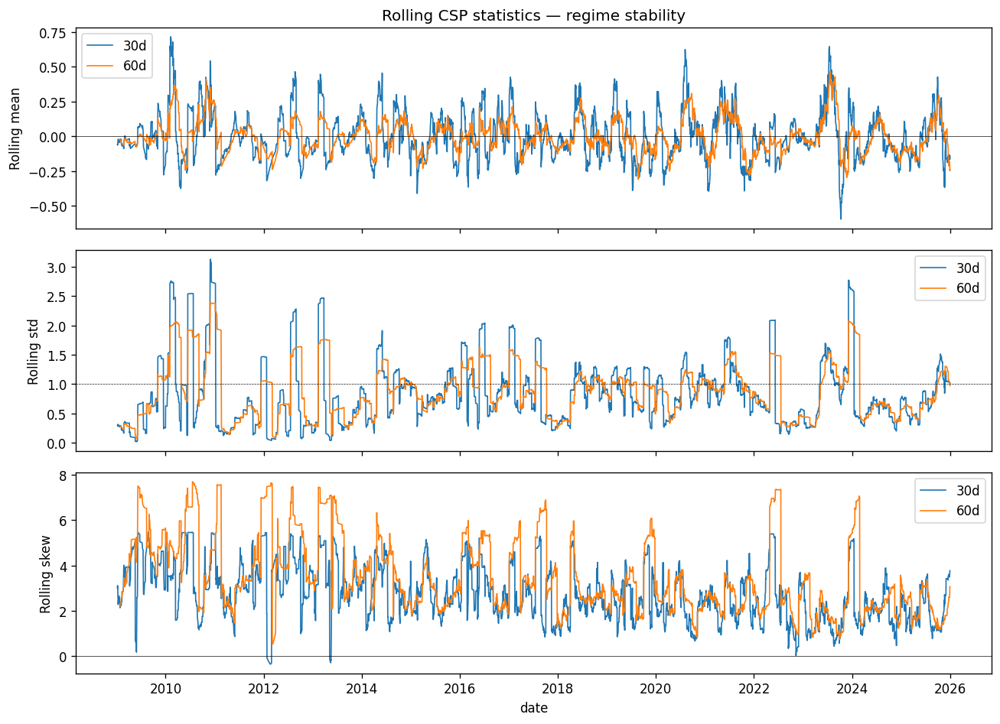

In [21]:
dsp_series = df["CSP"].dropna()
dates_dsp  = df.loc[dsp_series.index, "date"]
windows    = [30, 60]

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for w in windows:
    axes[0].plot(dates_dsp,
                 dsp_series.rolling(w, min_periods=w//2).mean(),
                 label=f"{w}d", lw=1)
    axes[1].plot(dates_dsp,
                 dsp_series.rolling(w, min_periods=w//2).std(),
                 label=f"{w}d", lw=1)
    axes[2].plot(dates_dsp,
                 dsp_series.rolling(w, min_periods=w//2).skew(),
                 label=f"{w}d", lw=1)

axes[0].axhline(0, color="k", lw=0.4)
axes[0].set_ylabel("Rolling mean")
axes[0].set_title("Rolling CSP statistics — regime stability")
axes[0].legend()
axes[1].axhline(1, color="k", lw=0.4, ls="--")
axes[1].set_ylabel("Rolling std")
axes[1].legend()
axes[2].axhline(0, color="k", lw=0.4)
axes[2].set_ylabel("Rolling skew")
axes[2].set_xlabel("date")
axes[2].legend()
fig.tight_layout()
fig.savefig(figdir / "rolling_dsp.png", dpi=130)
plt.show()

## SSI Structural Stability

### CUSUM test on SSI

In [22]:
ssi        = df["SSI"].dropna().values
ssi_dates  = df.loc[df["SSI"].notna(), "date"]

ssi_demeaned = ssi - ssi.mean()
cusum        = (np.cumsum(ssi_demeaned) /
                (ssi.std(ddof=1) * np.sqrt(len(ssi))))
boundary     = 1.358
cusum_breach = np.any(np.abs(cusum) > boundary)

print(f"CUSUM max |statistic| : {np.max(np.abs(cusum)):.3f}  "
      f"(5% boundary ~ {boundary:.3f})")
print(f"Structural break detected : {'YES' if cusum_breach else 'no'}")

CUSUM max |statistic| : 20.091  (5% boundary ~ 1.358)
Structural break detected : YES


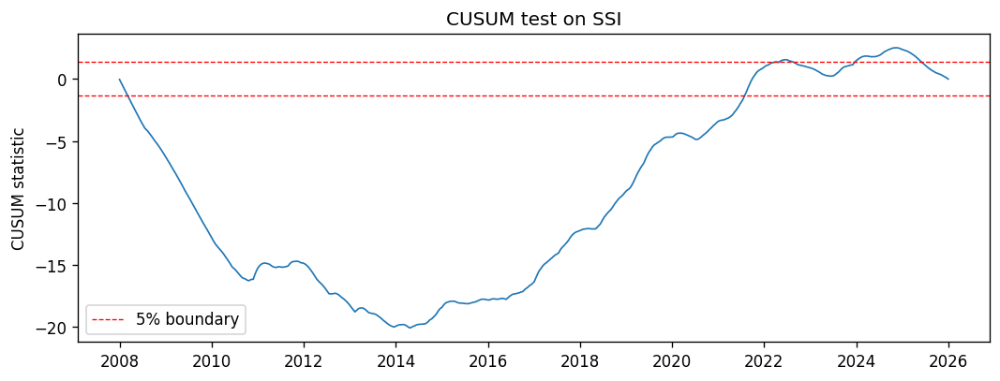

In [23]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(ssi_dates, cusum, lw=1)
ax.axhline( boundary, color="red", ls="--", lw=0.8, label="5% boundary")
ax.axhline(-boundary, color="red", ls="--", lw=0.8)
ax.set_title("CUSUM test on SSI")
ax.set_ylabel("CUSUM statistic")
ax.legend()
fig.tight_layout()
fig.savefig(figdir / "cusum_ssi.png", dpi=130)
plt.show()

## Unit-Root & Mean-Reversion Robustness

### Phillips-Perron

In [24]:
from scipy import stats as scipy_stats

def variance_ratio(x, q):
    n  = len(x)
    mu = np.mean(np.diff(x))
    sigma2_1 = np.var(np.diff(x), ddof=1)
    diffs_q  = x[q:] - x[:-q]
    sigma2_q = np.var(diffs_q, ddof=1) / q
    vr       = sigma2_q / sigma2_1
    z        = (vr - 1) / np.sqrt(2 * (2 * q - 1) * (q - 1) / (3 * q * n))
    return vr, z

print("phillips perron unit root test")
for col in ["SSI", "CSP"]:
    x = df[col].dropna().values
    adf_stat, adf_p, used_lag, *_ = adfuller(x, autolag="t-stat", regression="c")
    print(f"{col:5s}:  ADF(t-stat) stat={adf_stat:.3f}, p={adf_p:.4f}, lags={used_lag}")
print("(True Phillips-Perron uses Newey-West correction on the Dickey-Fuller")
print(" regression; this ADF variant is the closest statsmodels equivalent.)\n")


phillips perron unit root test
SSI  :  ADF(t-stat) stat=-3.893, p=0.0021, lags=23
CSP  :  ADF(t-stat) stat=-12.832, p=0.0000, lags=28
(True Phillips-Perron uses Newey-West correction on the Dickey-Fuller
 regression; this ADF variant is the closest statsmodels equivalent.)



### Variance Ratio Test

In [25]:
print("variance ratio test on CSP")
for q in [2, 5, 10]:
    vr, vr_z = variance_ratio(dsp, q)
    p_val    = 2 * (1 - scipy_stats.norm.cdf(abs(vr_z)))
    sig      = ("***" if p_val < 0.01 else
                "**"  if p_val < 0.05 else "")
    print(f"VR({q:2d}) = {vr:.4f},  z = {vr_z:+.3f},  p = {p_val:.4f} {sig}")
print("VR = 1 under random walk; VR > 1 = positive autocorrelation.")
print("Proposal expects CSP to be white noise -> VR near 1.")

variance ratio test on CSP
VR( 2) = 0.5225,  z = -31.839,  p = 0.0000 ***
VR( 5) = 0.2130,  z = -23.950,  p = 0.0000 ***
VR(10) = 0.1022,  z = -17.729,  p = 0.0000 ***
VR = 1 under random walk; VR > 1 = positive autocorrelation.
Proposal expects CSP to be white noise -> VR near 1.


## External Validation Against EM-Dat Events

### EM-DAT coincidence permutation test

In [26]:
import numpy as np
import pandas as pd

EMDAT_WINDOW    = 2
CSP_THRESHOLD   = 1.5
N_PERMUTATIONS  = 10_000
RANDOM_STATE    = 42

print("\n" + "═" * 80)
print("C1. EM-DAT COINCIDENCE PERMUTATION TEST")
print("═" * 80)
print(f"  |CSP| threshold : {CSP_THRESHOLD}")
print(f"  Window          : +/- {EMDAT_WINDOW} days")
print(f"  Permutations    : {N_PERMUTATIONS:,}")
print(f"  EM-DAT events   : {len(emdat_dates):,}")

rng = np.random.default_rng(RANDOM_STATE)
sub = df.dropna(subset=["CSP"]).copy().reset_index(drop=True)
sub["date"] = pd.to_datetime(sub["date"])

shock_idx = np.where(sub["CSP"].abs() >= CSP_THRESHOLD)[0]
cal       = sub["date"].values
emdat_arr = np.sort(np.array(
    pd.to_datetime(pd.Index(emdat_dates)), dtype="datetime64[D]"))

print(f"\n  Total CSP observations : {len(sub):,}")
print(f"  Shocks |CSP| >= {CSP_THRESHOLD}  : {len(shock_idx):,}")

if len(shock_idx) == 0:
    raise RuntimeError(
        f"No CSP observations exceed the |CSP| >= {CSP_THRESHOLD} threshold "
        f"in this sample — permutation test needs at least one shock to "
        f"compare against the null. Check date range covers a period "
        f"with real events, or lower CSP_THRESHOLD."
    )

def count_matches_fast(shock_dates_arr, event_dates_sorted, window_days):
    w  = np.timedelta64(window_days, 'D')
    lo = np.searchsorted(event_dates_sorted, shock_dates_arr - w, side="left")
    hi = np.searchsorted(event_dates_sorted, shock_dates_arr + w, side="right")
    return int(np.sum(hi > lo))

all_dates_arr = np.array(pd.to_datetime(cal), dtype="datetime64[D]")
shock_arr     = np.array(pd.to_datetime(cal[shock_idx]), dtype="datetime64[D]")

observed = count_matches_fast(shock_arr, emdat_arr, EMDAT_WINDOW)
obs_rate = observed / len(shock_idx)

print(f"\n  Observed matches : {observed}/{len(shock_idx)} ({obs_rate:.1%})")
print(f"  Running {N_PERMUTATIONS:,} permutations...")

null = np.array([
    count_matches_fast(
        rng.choice(all_dates_arr, size=len(shock_idx), replace=False),
        emdat_arr, EMDAT_WINDOW)
    for _ in range(N_PERMUTATIONS)
])

null_mean = null.mean()
null_std  = null.std()
null_rate = null_mean / len(shock_idx)
p_val     = float((null >= observed).mean())
pct       = float((null <= observed).mean()) * 100

print(f"  Null mean        : {null_mean:.2f} ({null_rate:.1%})")
print(f"  Null std         : {null_std:.2f}")
print(f"  p-value          : {p_val:.4f}")
print(f"  Significant      : {'Yes ✓' if p_val < 0.05 else 'No ✗'}")
print(f"  Obs percentile   : {pct:.1f}th of null distribution")


════════════════════════════════════════════════════════════════════════════════
C1. EM-DAT COINCIDENCE PERMUTATION TEST
════════════════════════════════════════════════════════════════════════════════
  |CSP| threshold : 1.5
  Window          : +/- 2 days
  Permutations    : 10,000
  EM-DAT events   : 417

  Total CSP observations : 4,445
  Shocks |CSP| >= 1.5  : 216

  Observed matches : 73/216 (33.8%)
  Running 10,000 permutations...
  Null mean        : 59.58 (27.6%)
  Null std         : 6.34
  p-value          : 0.0221
  Significant      : Yes ✓
  Obs percentile   : 98.4th of null distribution


In [27]:
r = CheckResult(
    "EM-DAT coincidence (permutation)",
    p_val < 0.05,
    f"observed={observed}/{len(shock_idx)} ({obs_rate:.1%}), "
    f"null mean={null_mean:.2f} ({null_rate:.1%}), p={p_val:.4f}",
    f"window=+/-{EMDAT_WINDOW}d, |CSP|>={CSP_THRESHOLD}, "
    f"B={N_PERMUTATIONS:,}, obs percentile={pct:.1f}th")
results.append(r); r.show()

[ PASS ]  EM-DAT coincidence (permutation)                         observed=73/216 (33.8%), null mean=59.58 (27.6%), p=0.0221
          note: window=+/-2d, |CSP|>=1.5, B=10,000, obs percentile=98.4th


### Window sensitivity

In [28]:
rng_w     = np.random.default_rng(RANDOM_STATE)
windows   = list(range(1, 31))
B_sweep   = 2_000
hit_rates, null_means, null_95 = [], [], []

for w in windows:
    w_arr = np.timedelta64(w, 'D')
    lo    = np.searchsorted(emdat_arr, shock_arr - w_arr, side="left")
    hi    = np.searchsorted(emdat_arr, shock_arr + w_arr, side="right")
    hits  = int(np.sum(hi > lo))
    rate  = hits / len(shock_arr)

    null_w = np.array([
        count_matches_fast(
            rng_w.choice(all_dates_arr, size=len(shock_arr), replace=False),
            emdat_arr, w)
        for _ in range(B_sweep)
    ]) / len(shock_arr)

    hit_rates.append(rate)
    null_means.append(null_w.mean())
    null_95.append(np.percentile(null_w, 95))

print(f"{'Window (±d)':<14s} {'Hit rate':<12s} {'Null mean':<12s} "
      f"{'Null 95th':<12s} {'Significant?'}")
for i, w in enumerate(windows):
    sig = "YES" if hit_rates[i] > null_95[i] else "no"
    print(f"±{w:<12d} {hit_rates[i]:<12.3f} {null_means[i]:<12.3f} "
          f"{null_95[i]:<12.3f} {sig}")


Window (±d)    Hit rate     Null mean    Null 95th    Significant?
±1            0.204        0.172        0.213        no
±2            0.338        0.275        0.320        YES
±3            0.463        0.369        0.421        YES
±4            0.546        0.450        0.505        YES
±5            0.630        0.518        0.569        YES
±6            0.667        0.572        0.625        YES
±7            0.708        0.621        0.671        YES
±8            0.750        0.664        0.713        YES
±9            0.773        0.702        0.750        YES
±10           0.801        0.732        0.782        YES
±11           0.815        0.761        0.806        YES
±12           0.824        0.785        0.829        no
±13           0.833        0.806        0.852        no
±14           0.852        0.823        0.866        no
±15           0.856        0.838        0.880        no
±16           0.861        0.851        0.889        no
±17           0.875        

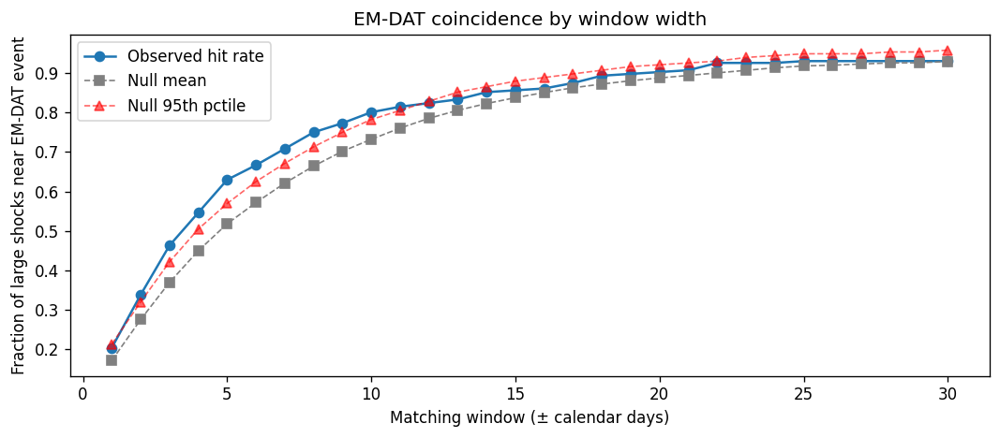

In [29]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(windows, hit_rates, "o-",  label="Observed hit rate", lw=1.5)
ax.plot(windows, null_means, "s--", color="grey", label="Null mean", lw=1)
ax.plot(windows, null_95,   "^--", color="red",  alpha=0.6,
        label="Null 95th pctile", lw=1)
ax.set_xlabel("Matching window (± calendar days)")
ax.set_ylabel("Fraction of large shocks near EM-DAT event")
ax.set_title("EM-DAT coincidence by window width")
ax.legend()
fig.tight_layout()
fig.savefig(figdir / "f2_coincidence_sweep.png", dpi=130)
plt.show()

### Offset Analysis

In [30]:
dates       = sub["date"].values
csp_full    = sub["CSP"].values
spike_mask  = np.abs(csp_full) >= CSP_THRESHOLD
spike_dates = dates[spike_mask]

valid_csp           = sub.dropna(subset=["CSP"]).copy()
valid_csp["abs_csp"] = valid_csp["CSP"].abs()
top10       = valid_csp.nlargest(10, "abs_csp")
top10_dates = top10["date"].values

print(f"Large-spike dates (|CSP| >= {CSP_THRESHOLD}): {len(spike_dates)}")
print()
print(f"{'EM-DAT event':<35s} {'Nearest spike':<14s} {'Offset':>13s} "
      f"{'CSP':>10s}     {'Nearest top-10':<14s} {'Offset top-10':>13s}")
print(f"{'-'*35} {'-'*14} {'-'*13} {'-'*10}     {'-'*14} {'-'*13}")

offsets_all = []
for edate_str, label, etype in EMDAT_EVENTS:
    edate = np.datetime64(edate_str)

    if len(spike_dates) > 0:
        diffs       = (spike_dates.astype("datetime64[D]") -
                       edate.astype("datetime64[D]")).astype(int)
        nearest_idx = np.argmin(np.abs(diffs))
        spike_d     = spike_dates[nearest_idx]
        offset      = int(diffs[nearest_idx])
        row         = sub[sub["date"] == spike_d]
        csp_val     = float(row["CSP"].iloc[0]) if len(row) else np.nan
    else:
        spike_d, offset, csp_val = None, np.nan, np.nan

    diffs10       = (top10_dates.astype("datetime64[D]") -
                     edate.astype("datetime64[D]")).astype(int)
    nearest10_idx = np.argmin(np.abs(diffs10))
    top10_d       = top10_dates[nearest10_idx]
    offset10      = int(diffs10[nearest10_idx])

    offsets_all.append({
        "event":        label,
        "type":         etype,
        "event_date":   edate_str,
        "offset_spike": offset,
        "offset_top10": offset10,
        "csp_spike":    csp_val,
    })

    print(f"{label:<35s} {str(spike_d)[:10]:<14s} {offset:+d} days"
          f"{csp_val:>14.3f}     {str(top10_d)[:10]:<14s} {offset10:+d} days")

offsets_df = pd.DataFrame(offsets_all)
acute      = offsets_df[offsets_df["type"] == "acute"]
chronic    = offsets_df[offsets_df["type"] == "chronic"]


display(offsets_df.sort_values("offset_spike").reset_index(drop=True))

Large-spike dates (|CSP| >= 1.5): 216

EM-DAT event                        Nearest spike         Offset        CSP     Nearest top-10 Offset top-10
----------------------------------- -------------- ------------- ----------     -------------- -------------
Drought                             2023-12-06     -26 days        13.630     2023-12-06     -26 days
Storm                               2022-11-30     -26 days         2.386     2022-04-28     -242 days
Storm                               2018-04-05     +35 days         4.570     2017-07-18     -226 days
Earthquake                          2016-11-04     -3 days         1.996     2017-01-04     +58 days
Earthquake                          2019-07-16     +11 days         1.504     2017-07-18     -717 days
Storm                               2022-11-30     -19 days         2.386     2022-04-28     -235 days
Volcanic activity                   2018-05-03     +0 days         3.518     2017-07-18     -289 days
Storm                     

,event,type,event_date,offset_spike,offset_top10,csp_spike
0,Wildfire,chronic,2022-07-29,-92,-92,11.057461
1,Storm,acute,2018-01-03,-91,-169,2.125284
2,Drought,chronic,2018-01-01,-89,-167,2.125284
3,Flood,acute,2022-07-26,-89,-89,11.057461
4,Storm,acute,2017-12-31,-88,-166,2.125284
...,...,...,...,...,...,...
412,Earthquake,acute,2008-02-21,369,712,1.507090
413,Storm,acute,2008-02-05,385,728,1.507090
414,Storm,acute,2008-01-29,392,735,1.507090
415,Flood,acute,2008-01-05,416,759,1.507090


In [31]:
print("\n" + "─" * 80)
if len(acute) > 0:
    print(f"Acute events ({len(acute):,})")
    print(f"  Median offset to nearest spike  : {acute['offset_spike'].median():+.0f} days")
    print(f"  Median offset to nearest top-10 : {acute['offset_top10'].median():+.0f} days")
    print(f"  Mean |offset| to nearest spike  : {acute['offset_spike'].abs().mean():.1f} days")
if len(chronic) > 0:
    print(f"Chronic events ({len(chronic):,})")
    print(f"  Median offset to nearest spike  : {chronic['offset_spike'].median():+.0f} days")
    print(f"  Mean |offset| to nearest spike  : {chronic['offset_spike'].abs().mean():.1f} days")


────────────────────────────────────────────────────────────────────────────────
Acute events (369)
  Median offset to nearest spike  : +0 days
  Median offset to nearest top-10 : +26 days
  Mean |offset| to nearest spike  : 29.6 days
Chronic events (48)
  Median offset to nearest spike  : -2 days
  Mean |offset| to nearest spike  : 23.1 days


### Top-10 spikes and event-window plots

In [32]:
# ── Top-10 spikes ─────────────────────────────────────────────────────────────
topk = (df.dropna(subset=["CSP"])
          .assign(abs_csp=lambda x: x["CSP"].abs())
          .nlargest(10, "abs_csp")
          [["date", "CSP", "S_daily_raw", "SSI"]]
          .reset_index(drop=True))
display(topk)

,date,CSP,S_daily_raw,SSI
0,2010-11-29,14.542452,0.250145,0.008612
1,2010-06-15,13.655174,0.068479,0.002068
2,2023-12-06,13.629554,0.106596,0.005614
3,2013-02-12,12.806961,0.172996,0.004943
4,2010-02-02,12.499966,0.030504,0.001246
5,2012-07-20,11.116678,0.103525,0.003182
6,2022-04-28,11.057461,0.111730,0.005079
7,2017-01-04,9.862149,0.109919,0.006941
8,2016-05-26,9.755041,0.083075,0.004252
9,2017-07-18,9.158245,0.119350,0.006859


In [33]:
import matplotlib.pyplot as plt

# Event-window bar plots ±15 days around each EM-DAT event 
window_days = 15

fig, axes = plt.subplots(
    len(EMDAT_EVENTS), 2,
    figsize=(13, 3 * len(EMDAT_EVENTS)),
    sharex=False)

if len(EMDAT_EVENTS) == 1:
    axes = axes.reshape(1, -1)

for row_i, (edate_str, label, etype) in enumerate(EMDAT_EVENTS):
    edate = pd.Timestamp(edate_str)
    mask  = ((df["date"] >= edate - pd.Timedelta(days=window_days)) &
             (df["date"] <= edate + pd.Timedelta(days=window_days)))
    sub_e = df[mask].copy()

    if len(sub_e) == 0:
        continue

    sub_e["rel_day"] = (sub_e["date"] - edate).dt.days

    ax_raw = axes[row_i, 0]
    ax_csp = axes[row_i, 1]

    ax_raw.bar(sub_e["rel_day"], sub_e["S_daily_raw"],
               color="steelblue", alpha=0.7, width=0.8)
    ax_raw.set_ylabel("S_raw")
    ax_raw.set_title(f"{label}  [{edate_str}]", fontsize=9, fontweight="bold")

    tick_days  = sub_e["rel_day"].values[::3]
    tick_dates = [(edate + pd.Timedelta(days=int(d))).strftime("%b %d")
                  for d in tick_days]
    ax_raw.set_xticks(tick_days)
    ax_raw.set_xticklabels(tick_dates, rotation=45, ha="right", fontsize=7)
    ax_raw.axvline(0, color="red", ls="--", lw=1.2,
                   label=f"EM-DAT: {edate_str}")
    ax_raw.legend(fontsize=7)

    csp_sub = sub_e.dropna(subset=["CSP"])
    if len(csp_sub) > 0:
        colors = ["C3" if v > 0 else "C0" for v in csp_sub["CSP"]]
        ax_csp.bar(csp_sub["rel_day"], csp_sub["CSP"],
                   color=colors, alpha=0.7, width=0.8)

    ax_csp.axvline(0, color="red", ls="--", lw=1.2,
                   label=f"EM-DAT: {edate_str}")
    ax_csp.axhline(0, color="k", lw=0.4)
    ax_csp.set_ylabel("CSP")
    ax_csp.set_title(f"{label} — CSP  [{edate_str}]", fontsize=9, fontweight="bold")
    ax_csp.legend(fontsize=7)

    ax_csp.set_xticks(tick_days)
    ax_csp.set_xticklabels(tick_dates, rotation=45, ha="right", fontsize=7)

axes[-1, 0].set_xlabel("Date")
axes[-1, 1].set_xlabel("Date")
fig.suptitle("Event-window responses (±15 days around EM-DAT)",
             y=1.01, fontsize=12)
fig.tight_layout()
fig.savefig(figdir / "fevent_windows.png", dpi=130, bbox_inches="tight")
plt.show()
print("Event-window plots saved.")

Event-window plots saved.


## Specfication Robustness

### Half Life Sensitivity

In [34]:
def hl_to_lambda(hl):
    return np.exp(-np.log(2) / hl)

def ewma(x, lam, init=0.0):
    out = np.empty_like(x, dtype=float)
    out[0] = init
    for i in range(1, len(x)):
        v = x[i] if not np.isnan(x[i]) else 0.0
        out[i] = lam * out[i-1] + (1 - lam) * v
    return out

s        = df["S_daily_raw"].fillna(0.0).values
baseline = df["SSI"].values
rows     = []

for hl in (15, 30, 45, 90):
    lam     = hl_to_lambda(hl)
    ssi_alt = ewma(s, lam, init=s[0])
    rows.append({
        "half_life_bdays":      hl,
        "lambda":               round(lam, 6),
        "ssi_mean":             round(float(ssi_alt.mean()), 6),
        "ssi_std":              round(float(ssi_alt.std(ddof=1)), 6),
        "corr_with_baseline_SSI": round(
            float(np.corrcoef(baseline, ssi_alt)[0, 1]), 6),
    })

sens = pd.DataFrame(rows)
display(sens)

,half_life_bdays,lambda,ssi_mean,ssi_std,corr_with_baseline_SSI
0,15,0.954842,0.003195,0.001888,0.960808
1,30,0.977160,0.003185,0.001642,1.000000
2,45,0.984715,0.003175,0.001544,0.987955
3,90,0.992328,0.003142,0.001436,0.923785


### AR order sensitivity

In [35]:
import warnings
from statsmodels.tsa.ar_model import AutoReg

s_tilde     = (df["S_daily_raw"].fillna(0.0) - df["SSI"].shift(1)).dropna()
ROLL_WINDOW = 252
MIN_PERIODS = 60

rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for p in [0, 1, 2, 5]:
        try:
            if p == 0:
                resid = s_tilde - s_tilde.mean()
            else:
                m     = AutoReg(s_tilde.values, lags=p, old_names=False).fit()
                resid = pd.Series(m.resid, index=s_tilde.index[p:])

            sd_roll = resid.rolling(ROLL_WINDOW, min_periods=MIN_PERIODS).std()
            csp     = (resid / sd_roll).dropna()
            lb      = acorr_ljungbox(csp.values, lags=[1, 5], return_df=True)

            rows.append({
                "AR_order_p":          p,
                "n_valid":             len(csp),
                "mean":                round(csp.mean(), 4),
                "std":                 round(csp.std(ddof=1), 4),
                "rho_1":               round(csp.autocorr(1), 4),
                "LB_p_lag1":           round(float(lb.loc[1, "lb_pvalue"]), 4),
                "LB_p_lag5":           round(float(lb.loc[5, "lb_pvalue"]), 4),
                "whiteness_lag1_pass": float(lb.loc[1, "lb_pvalue"]) > 0.05,
                "whiteness_lag5_pass": float(lb.loc[5, "lb_pvalue"]) > 0.05,
            })
        except Exception as e:
            print(f"  p={p}: {e}")

ar_sens = pd.DataFrame(rows)
display(ar_sens)

#  Reconstructs full CSP then confirm it matches saved CSP 
best_bic, best_p, best_resid = np.inf, 0, None

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for p in range(0, 6):
        try:
            if p == 0:
                resid  = s_tilde - s_tilde.mean()
                n      = len(resid)
                sigma2 = float((resid ** 2).mean())
                bic    = n * np.log(sigma2) + np.log(n) * 1
            else:
                m     = AutoReg(s_tilde.values, lags=p, old_names=False).fit()
                resid = pd.Series(m.resid, index=s_tilde.index[p:])
                bic   = float(m.bic)
        except Exception:
            continue
        if bic < best_bic:
            best_bic, best_p, best_resid = bic, p, resid

sd_roll   = best_resid.rolling(ROLL_WINDOW, min_periods=MIN_PERIODS).std()
csp_recon = best_resid / sd_roll

csp_pub = df["CSP"].dropna()
csp_rec = csp_recon.dropna()
common  = csp_pub.index.intersection(csp_rec.index)


,AR_order_p,n_valid,mean,std,rho_1,LB_p_lag1,LB_p_lag5,whiteness_lag1_pass,whiteness_lag5_pass
0,0,4637,0.002600,1.029500,0.028900,0.049000,0.094900,False,True
1,1,4636,0.002600,1.029300,0.009200,0.529100,0.306500,True,True
2,2,4635,0.002600,1.029000,0.009300,0.526000,0.352100,True,True
3,5,4632,0.002800,1.028300,0.011200,0.447100,0.091100,True,True


In [36]:
print(f"\nBest AR order (BIC)       : p = {best_p}")
print(f"corr(CSP_file, CSP_recon) : {csp_pub.loc[common].corr(csp_rec.loc[common]):+.4f}")
print(f"rho(1) CSP_file           : {np.corrcoef(csp_pub.values[:-1], csp_pub.values[1:])[0,1]:+.4f}")
print(f"rho(1) CSP_recon          : {np.corrcoef(csp_rec.values[:-1], csp_rec.values[1:])[0,1]:+.4f}")
print(f"mean CSP_recon            : {csp_rec.mean():+.4f}")
print(f"std  CSP_recon            : {csp_rec.std(ddof=1):.4f}")


Best AR order (BIC)       : p = 0
corr(CSP_file, CSP_recon) : +1.0000
rho(1) CSP_file           : +0.0373
rho(1) CSP_recon          : +0.0289
mean CSP_recon            : +0.0026
std  CSP_recon            : 1.0295


### ACF/PACF of S_tilde

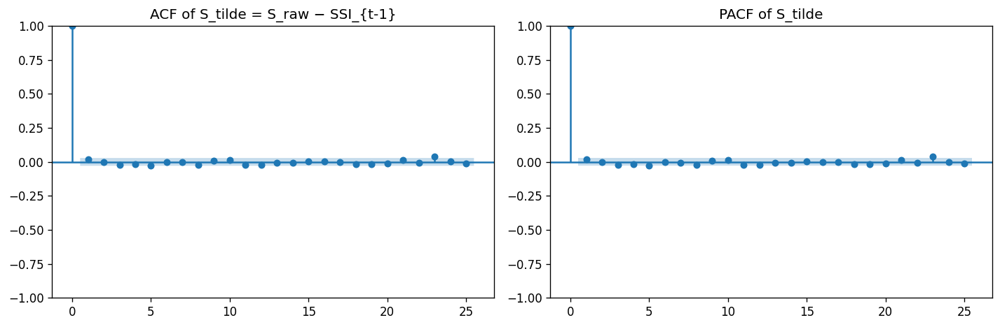

In [37]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import pacf

s_tilde = (df["S_daily_raw"].fillna(0.0) - df["SSI"].shift(1)).dropna()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
plot_acf( s_tilde, lags=25, ax=ax1,
          title="ACF of S_tilde = S_raw − SSI_{t-1}")
plot_pacf(s_tilde, lags=25, ax=ax2, method="ywm",
          title="PACF of S_tilde")
fig.tight_layout()
fig.savefig(figdir / "g7_acf_pacf_stilde.png", dpi=130)
plt.show()



In [38]:
pacf_vals = pacf(s_tilde, nlags=10, method="ywm")
print("PACF values (lags 1-10):")
for lag in range(1, 11):
    sig = " *" if abs(pacf_vals[lag]) > 1.96 / np.sqrt(len(s_tilde)) else ""
    print(f"  lag {lag:2d}: {pacf_vals[lag]:+.4f}{sig}")
print("(Significant lags suggest the AR order needed on the full sample.)")

PACF values (lags 1-10):
  lag  1: +0.0201
  lag  2: -0.0036
  lag  3: -0.0227
  lag  4: -0.0149
  lag  5: -0.0287 *
  lag  6: -0.0010
  lag  7: -0.0046
  lag  8: -0.0233
  lag  9: +0.0093
  lag 10: +0.0141
(Significant lags suggest the AR order needed on the full sample.)


### Convergent Validity

Convergent validity sample: 216 months

CSP_mean vs EM-DAT monthly count:
  Pearson  r = +nan  (p = nan)
  Spearman r = +nan  (p = nan)

CSP_max_abs vs EM-DAT monthly count:
  Pearson  r = +nan  (p = nan)
  Spearman r = +nan  (p = nan)

SSI_mean vs EM-DAT monthly count:
  Pearson  r = +0.1448  (p = 0.0335)
  Spearman r = +0.1794  (p = 0.0082)


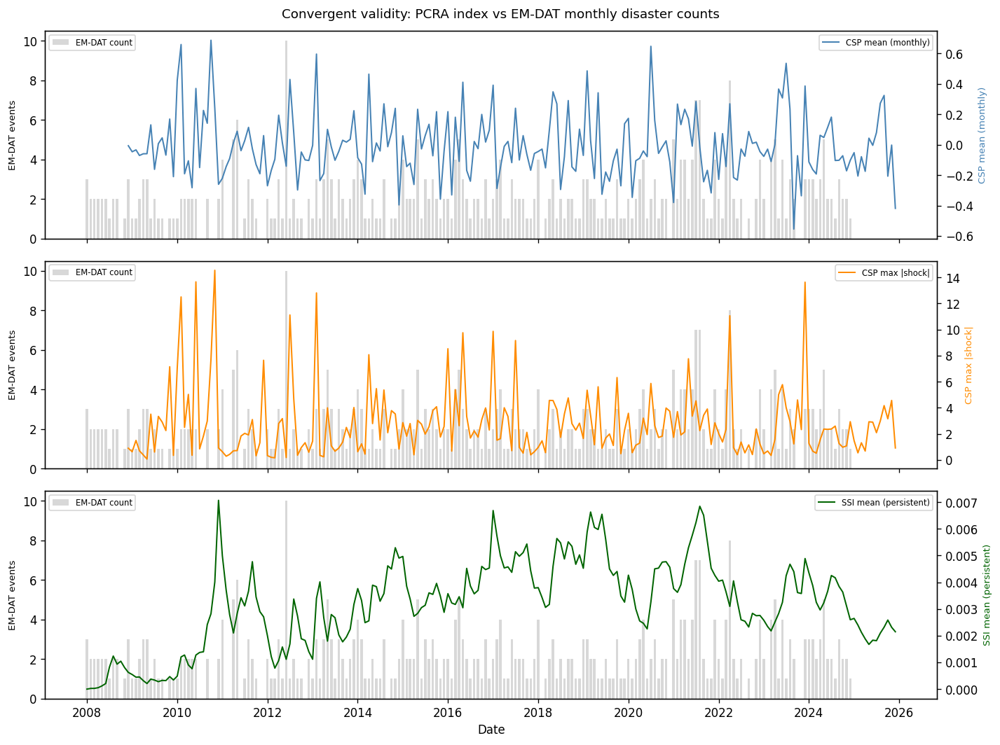

In [39]:
# Build monthly EM-DAT disaster count
emdat_monthly = (emdat_us
    .assign(date=lambda d: pd.to_datetime(d["event_date"])
            .dt.to_period("M").dt.to_timestamp())
    .groupby("date")
    .size()
    .reset_index(name="emdat_count"))

#  Monthly CSP aggregation 
csp_monthly_conv = (df[["date", "CSP", "SSI"]]
    .assign(date=lambda d: pd.to_datetime(d["date"])
            .dt.to_period("M").dt.to_timestamp())
    .groupby("date")
    .agg(
        CSP_mean    = ("CSP", "mean"),
        CSP_max_abs = ("CSP", lambda x: x.abs().max()),
        SSI_mean    = ("SSI", "mean"),
    )
    .reset_index())

#  Merge 
conv_df = csp_monthly_conv.merge(emdat_monthly, on="date", how="left")
conv_df["emdat_count"] = conv_df["emdat_count"].fillna(0)

print(f"Convergent validity sample: {len(conv_df):,} months")

#Correlations 
from scipy.stats import pearsonr, spearmanr

for csp_col in ["CSP_mean", "CSP_max_abs", "SSI_mean"]:
    pr, pp = pearsonr(conv_df[csp_col],     conv_df["emdat_count"])
    sr, sp = spearmanr(conv_df[csp_col],    conv_df["emdat_count"])
    print(f"\n{csp_col} vs EM-DAT monthly count:")
    print(f"  Pearson  r = {pr:+.4f}  (p = {pp:.4f})")
    print(f"  Spearman r = {sr:+.4f}  (p = {sp:.4f})")

# Plot
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

for ax, col, label, color in [
    (axes[0], "CSP_mean",    "CSP mean (monthly)",    "steelblue"),
    (axes[1], "CSP_max_abs", "CSP max |shock|",       "darkorange"),
    (axes[2], "SSI_mean",    "SSI mean (persistent)", "darkgreen"),
]:
    ax2 = ax.twinx()
    ax.bar(conv_df["date"], conv_df["emdat_count"],
           color="grey", alpha=0.3, width=20, label="EM-DAT count")
    ax2.plot(conv_df["date"], conv_df[col],
             color=color, lw=1.2, label=label)
    ax.set_ylabel("EM-DAT events", fontsize=8)
    ax2.set_ylabel(label, fontsize=8, color=color)
    ax.legend(loc="upper left",  fontsize=7)
    ax2.legend(loc="upper right", fontsize=7)

axes[-1].set_xlabel("Date")
fig.suptitle("Convergent validity: PCRA index vs EM-DAT monthly disaster counts",
             fontsize=11)
fig.tight_layout()
fig.savefig(figdir / "convergent_validity_emdat.png", dpi=150, bbox_inches="tight")
plt.show()

# Visuals

## NARRATIVE PLOTS — Daily

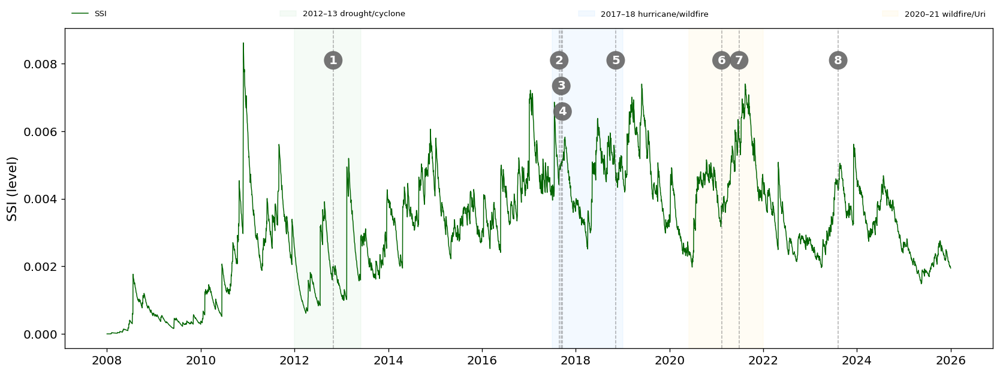

Saved: 01_daily_SSI.png


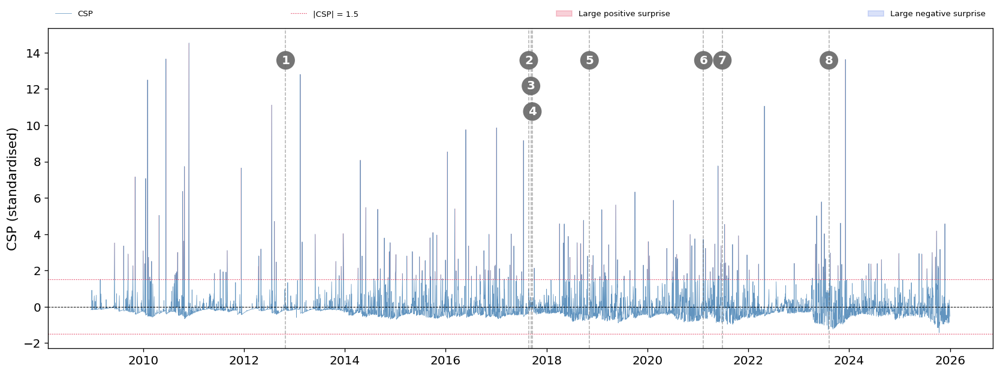

Saved: 02_daily_CSP.png


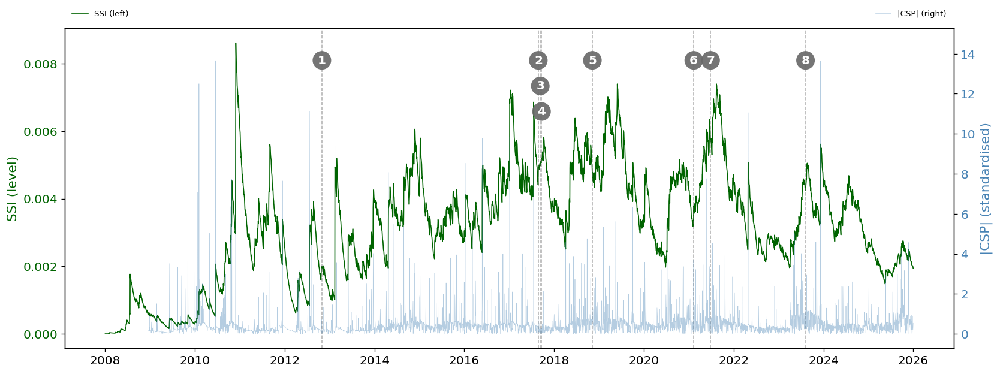

Saved: 03_daily_overlay.png


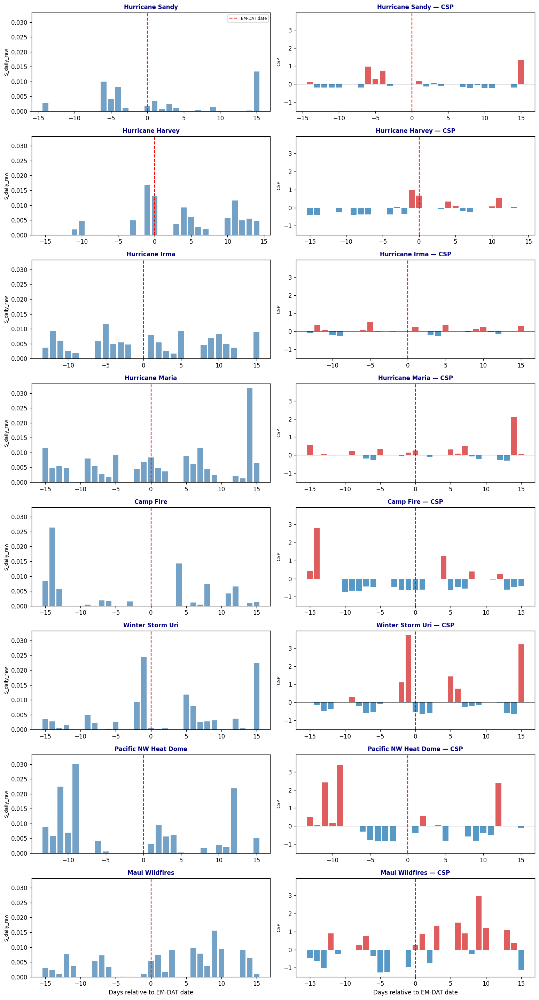

Saved: 04_daily_event_windows.png


In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path


df = df.copy()
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

emdat_us = emdat_us.copy()
emdat_us["event_date"] = pd.to_datetime(emdat_us["event_date"])
acute   = emdat_us[emdat_us["etype"] == "acute"].copy()
chronic = emdat_us[emdat_us["etype"] == "chronic"].copy()

WINDOW = 15   # ± days for event-window plots

# Key narrative events 
EMDAT_EVENTS = [
    ("2012-10-29", "Hurricane Sandy",       "acute"),
    ("2017-08-25", "Hurricane Harvey",      "acute"),
    ("2017-09-10", "Hurricane Irma",        "acute"),
    ("2017-09-20", "Hurricane Maria",       "acute"),
    ("2018-11-08", "Camp Fire",             "acute"),
    ("2021-02-10", "Winter Storm Uri",      "acute"),
    ("2021-06-27", "Pacific NW Heat Dome",  "acute"),
    ("2023-08-08", "Maui Wildfires",        "acute"),
]

EMDAT_LABELS = {
    "Hurricane Sandy":      1,
    "Hurricane Harvey":     2,
    "Hurricane Irma":       3,
    "Hurricane Maria":      4,
    "Camp Fire":            5,
    "Winter Storm Uri":     6,
    "Pacific NW Heat Dome": 7,
    "Maui Wildfires":       8,
}

def fmt_years(ax, every=2):
    ax.xaxis.set_major_locator(mdates.YearLocator(every))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

def add_numbered_vlines_top(ax, events=EMDAT_EVENTS, fontsize=12):
    """Dashed vline + big numbered circle near the top of the axes. The
    tight 2017 cluster (2=Harvey, 3=Irma, 4=Maria) is stacked with a
    step so the circles don't overlap each other."""
    ax.figure.canvas.draw()
    ylim  = ax.get_ylim()
    yspan = ylim[1] - ylim[0]
    TIER   = {1: 0, 2: 0, 3: 1, 4: 2, 5: 0, 6: 0, 7: 0, 8: 0}
    base_y = ylim[0] + 0.90 * yspan
    step   = 0.08 * yspan
    for edate_str, label, _ in events:
        ts   = pd.Timestamp(edate_str)
        num  = EMDAT_LABELS[label]
        ytop = base_y - TIER[num] * step
        ax.axvline(ts, color="dimgrey", lw=0.9, ls="--", alpha=0.55, ymin=0, zorder=2)
        ax.annotate(
            str(num),
            xy=(ts, ytop), xytext=(ts, ytop),
            ha="center", va="center",
            fontsize=fontsize, fontweight="bold", color="white",
            bbox=dict(boxstyle="circle,pad=0.3", fc="dimgrey", ec="none", alpha=0.92),
            zorder=5,
        )

def band_legend(ax, ncol, fontsize=8):
    """Legend as a horizontal band just ABOVE the axes, so it never
    overlaps the numbered circles drawn inside the plot."""
    h, l = ax.get_legend_handles_labels()
    if h:
        ax.legend(h, l, loc="lower left", bbox_to_anchor=(0, 1.01, 1, 0.2),
                  mode="expand", ncol=ncol, fontsize=fontsize, frameon=False)

def band_legend_twin(ax1, ax2, ncol, fontsize=8):
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc="lower left", bbox_to_anchor=(0, 1.01, 1, 0.2),
               mode="expand", ncol=ncol, fontsize=fontsize, frameon=False)

# Figure 1 — Daily SSI full sample

fig, ax = plt.subplots(figsize=(14, 5.3))   # extra headroom for the legend band

ax.plot(df["date"], df["SSI"], color="darkgreen", lw=0.9, label="SSI")

waves = [
    ("2012-01-01", "2013-06-01", "#d4edda", "2012–13 drought/cyclone"),
    ("2017-07-01", "2019-01-01", "#cce5ff", "2017–18 hurricane/wildfire"),
    ("2020-06-01", "2021-12-31", "#fff3cd", "2020–21 wildfire/Uri"),
]
for start, end, col, lbl in waves:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end),
               alpha=0.22, color=col, label=lbl)

ax.set_ylabel("SSI (level)", fontsize=13)
ax.tick_params(axis="both", labelsize=12)
fmt_years(ax)
add_numbered_vlines_top(ax)
band_legend(ax, ncol=4)
fig.tight_layout()
fig.savefig(figdir / "01_daily_SSI.png", dpi=180, bbox_inches="tight")
plt.show()
print("Saved: 01_daily_SSI.png")

# Figure 2 — Daily CSP full sample

fig, ax = plt.subplots(figsize=(14, 5.3))

ax.plot(df["date"], df["CSP"], color="steelblue", lw=0.45, alpha=0.85, label="CSP")
ax.axhline(0,    color="black",   lw=0.6, ls="--")
ax.axhline( 1.5, color="crimson", lw=0.7, ls=":", label="|CSP| = 1.5")
ax.axhline(-1.5, color="crimson", lw=0.7, ls=":")

ax.fill_between(df["date"], df["CSP"],  1.5,
                where=df["CSP"] >  1.5,
                color="crimson",   alpha=0.20, label="Large positive surprise")
ax.fill_between(df["date"], df["CSP"], -1.5,
                where=df["CSP"] < -1.5,
                color="royalblue", alpha=0.20, label="Large negative surprise")

ax.set_ylabel("CSP (standardised)", fontsize=13)
ax.tick_params(axis="both", labelsize=12)
fmt_years(ax)
add_numbered_vlines_top(ax)
band_legend(ax, ncol=4)
fig.tight_layout()
fig.savefig(figdir / "02_daily_CSP.png", dpi=180, bbox_inches="tight")
plt.show()
print("Saved: 02_daily_CSP.png")


# Figure 3 — Daily SSI and CSP dual-axis overlay   
csp_abs = df["CSP"].abs()

fig, ax1 = plt.subplots(figsize=(14, 5.3))
ax2 = ax1.twinx()

ax1.plot(df["date"], df["SSI"],   color="darkgreen", lw=1.0, label="SSI (left)")
ax2.plot(df["date"], csp_abs,     color="steelblue", lw=0.4, alpha=0.40, label="|CSP| (right)")

ax1.set_ylabel("SSI (level)",          color="darkgreen", fontsize=13)
ax2.set_ylabel("|CSP| (standardised)", color="steelblue", fontsize=13)
ax1.tick_params(axis="y", labelcolor="darkgreen", labelsize=12)
ax2.tick_params(axis="y", labelcolor="steelblue", labelsize=12)
ax1.tick_params(axis="x", labelsize=12)
fmt_years(ax1)
add_numbered_vlines_top(ax1)
band_legend_twin(ax1, ax2, ncol=2)
fig.tight_layout()
fig.savefig(figdir / "03_daily_overlay.png", dpi=180, bbox_inches="tight")
plt.show()
print("Saved: 03_daily_overlay.png")



# Figure 4 — Event-window bars ±WINDOW days
# Left = S_daily_raw,  Right = CSP

fig, axes = plt.subplots(len(EMDAT_EVENTS), 2,
                         figsize=(13, 3 * len(EMDAT_EVENTS)),
                         sharey="col")
if len(EMDAT_EVENTS) == 1:
    axes = axes.reshape(1, -1)

for row_i, (edate_str, label, etype) in enumerate(EMDAT_EVENTS):
    edate = pd.Timestamp(edate_str)
    mask  = ((df["date"] >= edate - pd.Timedelta(days=WINDOW)) &
             (df["date"] <= edate + pd.Timedelta(days=WINDOW)))
    sub   = df[mask].copy()
    if sub.empty:
        continue
    sub["rel_day"] = (sub["date"] - edate).dt.days

    ax_raw = axes[row_i, 0]
    ax_csp = axes[row_i, 1]

    # left: S_daily_raw
    ax_raw.bar(sub["rel_day"], sub["S_daily_raw"],
               color="steelblue", alpha=0.75, width=0.8)
    ax_raw.axvline(0, color="red", ls="--", lw=1.4, label="EM-DAT date")
    ax_raw.set_ylabel("S_daily_raw", fontsize=8)
    ax_raw.set_title(label, fontsize=10, fontweight="bold", color="navy")
    if row_i == 0:
        ax_raw.legend(fontsize=7)

    # right: CSP
    csp_sub = sub.dropna(subset=["CSP"])
    if not csp_sub.empty:
        colors = ["C3" if v > 0 else "C0" for v in csp_sub["CSP"]]
        ax_csp.bar(csp_sub["rel_day"], csp_sub["CSP"],
                   color=colors, alpha=0.75, width=0.8)
    ax_csp.axvline(0, color="red", ls="--", lw=1.4)
    ax_csp.axhline(0, color="k",   lw=0.4)
    ax_csp.set_ylabel("CSP", fontsize=8)
    ax_csp.set_title(f"{label} — CSP", fontsize=10, fontweight="bold", color="navy")

axes[-1, 0].set_xlabel("Days relative to EM-DAT date")
axes[-1, 1].set_xlabel("Days relative to EM-DAT date")
fig.tight_layout()
fig.savefig(figdir / "04_daily_event_windows.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: 04_daily_event_windows.png")

## Narrative investigation

CSP shocks, SSI turning points, EM-DAT matches

TOP 30 POSITIVE CSP SHOCKS
         date       CSP      SSI
1  2010-11-29 14.542452 0.008612
2  2010-06-15 13.655174 0.002068
3  2023-12-06 13.629554 0.005614
4  2013-02-12 12.806961 0.004943
5  2010-02-02 12.499966 0.001246
6  2012-07-20 11.116678 0.003182
7  2022-04-28 11.057461 0.005079
8  2017-01-04  9.862149 0.006941
9  2016-05-26  9.755041 0.004252
10 2017-07-18  9.158245 0.006859
11 2016-01-14  8.530353 0.004120
12 2014-04-23  8.071824 0.003392
13 2021-05-27  7.761230 0.006036
14 2010-10-27  7.731819 0.004534
15 2011-12-13  7.646077 0.003393
16 2009-11-04  7.151778 0.000503
17 2010-01-19  7.069312 0.000675
18 2010-10-14  6.361667 0.002917
19 2019-10-03  6.322122 0.005066
20 2020-07-08  5.870225 0.003237
21 2023-06-15  5.779893 0.003475
22 2019-05-17  5.614319 0.006254
23 2014-06-02  5.472614 0.004456
24 2016-03-07  5.394892 0.003350
25 2014-08-27  5.368667 0.004642
26 2019-02-05  5.352314 0.005735
27 2010-04-27  5.030620 0.001032
28 2023-05-11  5.013723 0.003046
29 2018-09-26  4

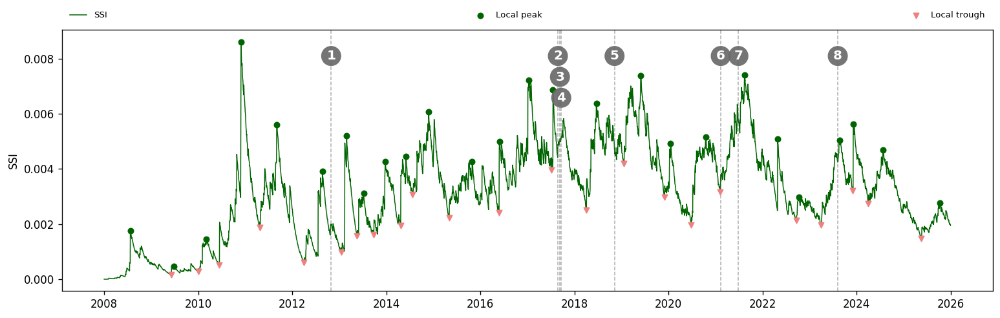

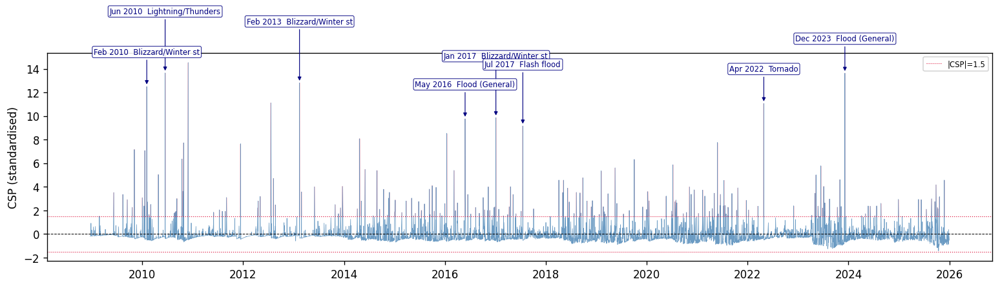

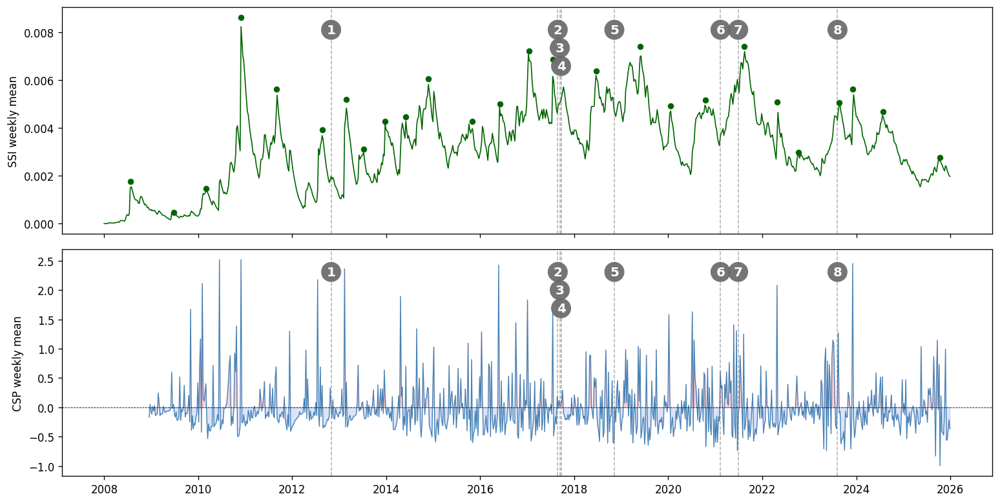

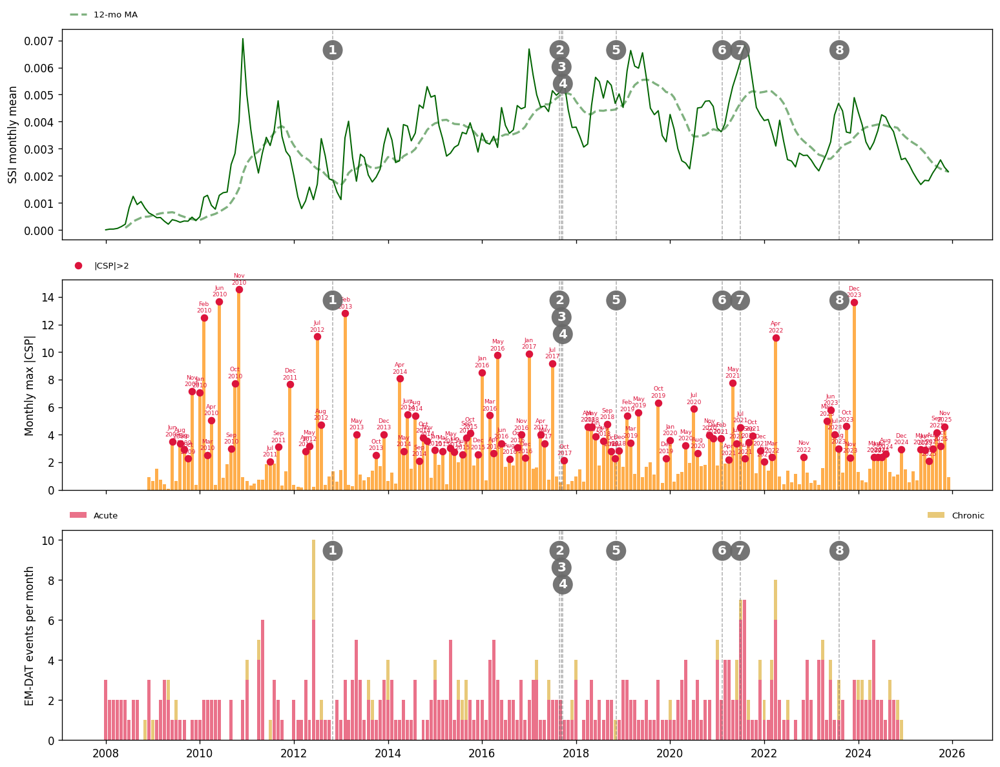

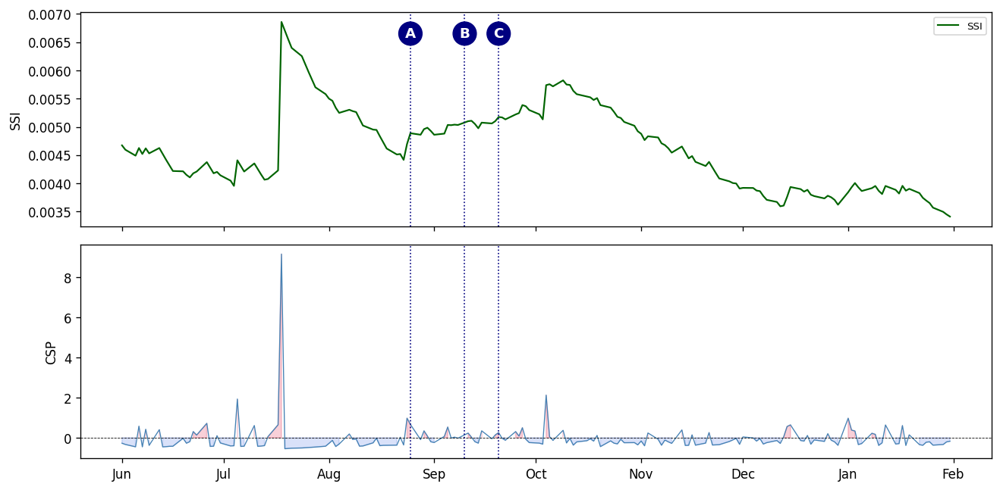

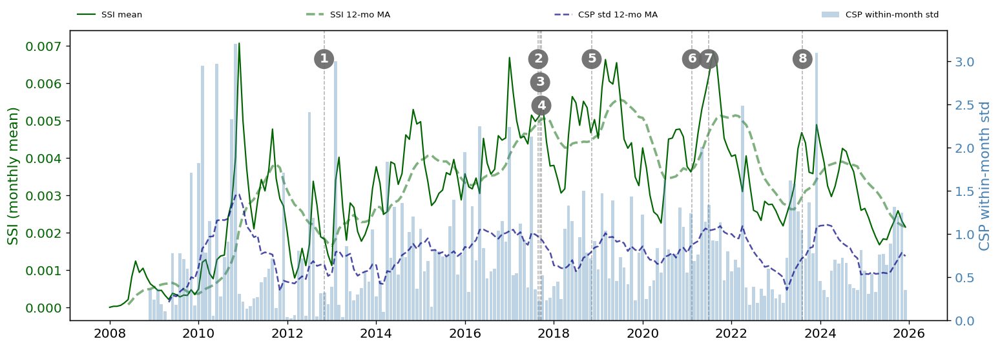


✓ All figures saved to /Users/adam/Desktop/PCRA Index Thesis/Visuals/Index-Level
✓ Investigation complete.


In [41]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.signal import argrelextrema
from pathlib import Path


df = df.copy()
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

emdat_us = emdat_us.copy()
emdat_us["event_date"] = pd.to_datetime(emdat_us["event_date"])

acute = emdat_us[emdat_us["etype"] == "acute"].copy()

#Shared event numbering 
EMDAT_LABELS = {
    "Hurricane Sandy":      1,
    "Hurricane Harvey":     2,
    "Hurricane Irma":       3,
    "Hurricane Maria":      4,
    "Camp Fire":            5,
    "Winter Storm Uri":     6,
    "Pacific NW Heat Dome": 7,
    "Maui Wildfires":       8,
}
KEY_EVENTS = [
    ("2012-10-29", "Hurricane Sandy",      "acute"),
    ("2017-08-25", "Hurricane Harvey",     "acute"),
    ("2017-09-10", "Hurricane Irma",       "acute"),
    ("2017-09-20", "Hurricane Maria",      "acute"),
    ("2018-11-08", "Camp Fire",            "acute"),
    ("2021-02-10", "Winter Storm Uri",     "acute"),
    ("2021-06-27", "Pacific NW Heat Dome", "acute"),
    ("2023-08-08", "Maui Wildfires",       "acute"),
]

def add_numbered_vlines_top(ax, events=KEY_EVENTS, fontsize=12):
    """Dashed vline + big numbered circle near the top of the axes. The
    tight 2017 cluster (2=Harvey, 3=Irma, 4=Maria) is stacked with a
    step so the circles don't overlap each other."""
    ax.figure.canvas.draw()
    ylim  = ax.get_ylim()
    yspan = ylim[1] - ylim[0]
    TIER   = {1: 0, 2: 0, 3: 1, 4: 2, 5: 0, 6: 0, 7: 0, 8: 0}
    base_y = ylim[0] + 0.90 * yspan
    step   = 0.08 * yspan
    for edate_str, label, _ in events:
        ts   = pd.Timestamp(edate_str)
        num  = EMDAT_LABELS[label]
        ytop = base_y - TIER[num] * step
        ax.axvline(ts, color="dimgrey", lw=0.9, ls="--", alpha=0.55, ymin=0, zorder=2)
        ax.annotate(
            str(num),
            xy=(ts, ytop), xytext=(ts, ytop),
            ha="center", va="center",
            fontsize=fontsize, fontweight="bold", color="white",
            bbox=dict(boxstyle="circle,pad=0.3", fc="dimgrey", ec="none", alpha=0.92),
            zorder=5,
        )

def band_legend(ax, ncol, fontsize=8):
    """Legend as a horizontal band just ABOVE the axes, so it never
    overlaps the numbered circles drawn inside the plot."""
    h, l = ax.get_legend_handles_labels()
    if h:
        ax.legend(h, l, loc="lower left", bbox_to_anchor=(0, 1.01, 1, 0.2),
                  mode="expand", ncol=ncol, fontsize=fontsize, frameon=False)

def fmt_years(ax, every=2):
    ax.xaxis.set_major_locator(mdates.YearLocator(every))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))


# 1. BIGGEST CSP SHOCKS — top 30 positive and negative
print("=" * 70)
print("TOP 30 POSITIVE CSP SHOCKS")
print("=" * 70)
top_pos = (df.dropna(subset=["CSP"])
             .nlargest(30, "CSP")
             [["date", "CSP", "SSI"]]
             .reset_index(drop=True))
top_pos.index += 1
print(top_pos.to_string())

print("\n" + "=" * 70)
print("TOP 30 NEGATIVE CSP SHOCKS")
print("=" * 70)
top_neg = (df.dropna(subset=["CSP"])
             .nsmallest(30, "CSP")
             [["date", "CSP", "SSI"]]
             .reset_index(drop=True))
top_neg.index += 1
print(top_neg.to_string())


# 2. EACH BIG SHOCK — find EM-DAT events within ±7 days
WINDOW = 7

print("\n" + "=" * 70)
print(f"EM-DAT EVENTS WITHIN ±{WINDOW} DAYS OF TOP-30 POSITIVE CSP SHOCKS")
print("=" * 70)

for _, row in top_pos.iterrows():
    spike_date = row["date"]
    nearby = emdat_us[
        (emdat_us["event_date"] >= spike_date - pd.Timedelta(days=WINDOW)) &
        (emdat_us["event_date"] <= spike_date + pd.Timedelta(days=WINDOW))
    ][["event_date", "Disaster Subtype", "etype"]].copy()
    nearby["offset_days"] = (nearby["event_date"] - spike_date).dt.days

    print(f"\n  CSP = {row['CSP']:+.3f}  |  date = {spike_date.date()}  |  SSI = {row['SSI']:.5f}")
    if len(nearby):
        print(nearby.to_string(index=False))
    else:
        print("    [no EM-DAT event within window]")


# 3. SSI TURNING POINTS — local maxima and minima

ssi = df["SSI"].values
peaks   = argrelextrema(ssi, np.greater, order=60)[0]
troughs = argrelextrema(ssi, np.less,    order=60)[0]

print("\n" + "=" * 70)
print("SSI LOCAL MAXIMA (attention peaks)")
print("=" * 70)
peak_df = df.iloc[peaks][["date", "SSI"]].reset_index(drop=True)
peak_df.index += 1
print(peak_df.to_string())

print("\n" + "=" * 70)
print("SSI LOCAL MINIMA (attention troughs)")
print("=" * 70)
trough_df = df.iloc[troughs][["date", "SSI"]].reset_index(drop=True)
trough_df.index += 1
print(trough_df.to_string())


# 4. MONTHLY SUMMARY TABLE
monthly = (df
    .assign(month=lambda d: d["date"].dt.to_period("M").dt.to_timestamp())
    .groupby("month")
    .agg(
        SSI_mean    = ("SSI", "mean"),
        CSP_mean    = ("CSP", "mean"),
        CSP_max_abs = ("CSP", lambda x: x.abs().max()),
        CSP_std     = ("CSP", "std"),
        n_big_pos   = ("CSP", lambda x: (x >  1.5).sum()),
        n_big_neg   = ("CSP", lambda x: (x < -1.5).sum()),
    )
    .reset_index()
    .rename(columns={"month": "date"}))

emdat_monthly = (emdat_us
    .assign(date=lambda d: d["event_date"].dt.to_period("M").dt.to_timestamp())
    .groupby("date").size().reset_index(name="emdat_count"))

monthly = monthly.merge(emdat_monthly, on="date", how="left")
monthly["emdat_count"] = monthly["emdat_count"].fillna(0).astype(int)

pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_rows", 300)

print("\n" + "=" * 70)
print("FULL MONTHLY SUMMARY TABLE")
print("=" * 70)
print(monthly.to_string(index=False))

print("\n--- TOP 15 MONTHS BY MAX|CSP| ---")
print(monthly.nlargest(15, "CSP_max_abs")
      [["date","CSP_mean","CSP_max_abs","SSI_mean","emdat_count"]]
      .to_string(index=False))

print("\n--- TOP 15 MONTHS BY EM-DAT COUNT ---")
print(monthly.nlargest(15, "emdat_count")
      [["date","CSP_mean","CSP_max_abs","SSI_mean","emdat_count"]]
      .to_string(index=False))

print("\n--- MOST NEGATIVE CSP MONTHS (attention troughs) ---")
print(monthly.nsmallest(10, "CSP_mean")
      [["date","CSP_mean","CSP_max_abs","SSI_mean","emdat_count"]]
      .to_string(index=False))


# 5. PLOTS

# Plot 1: Daily SSI 
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.plot(df["date"], df["SSI"], color="darkgreen", lw=0.9, label="SSI")
ax.scatter(df.iloc[peaks]["date"],   df.iloc[peaks]["SSI"],
           color="darkgreen", s=25, zorder=5, label="Local peak")
ax.scatter(df.iloc[troughs]["date"], df.iloc[troughs]["SSI"],
           color="lightcoral", s=25, zorder=5, marker="v", label="Local trough")
ax.set_ylabel("SSI")
fmt_years(ax)
add_numbered_vlines_top(ax)
band_legend(ax, ncol=3)
fig.tight_layout()
fig.savefig(figdir / "01_daily_SSI.png", dpi=170, bbox_inches="tight")
plt.show()

#  Plot 2: Daily CSP with top-10 labelled 
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(df["date"], df["CSP"], color="steelblue", lw=0.45, alpha=0.8)
ax.axhline(0,    color="black",   lw=0.6, ls="--")
ax.axhline( 1.5, color="crimson", lw=0.7, ls=":", label="|CSP|=1.5")
ax.axhline(-1.5, color="crimson", lw=0.7, ls=":")
ax.fill_between(df["date"], df["CSP"],  1.5, where=df["CSP"] >  1.5,
                color="crimson",   alpha=0.22)
ax.fill_between(df["date"], df["CSP"], -1.5, where=df["CSP"] < -1.5,
                color="royalblue", alpha=0.22)

top10 = df.dropna(subset=["CSP"]).nlargest(10, "CSP")

for i, (_, r) in enumerate(top10.iterrows()):
    nearby = emdat_us[
        (emdat_us["event_date"] >= r["date"] - pd.Timedelta(days=3)) &
        (emdat_us["event_date"] <= r["date"] + pd.Timedelta(days=3))
    ]
    if len(nearby) == 0:          # skip spikes with no EM-DAT match
        continue
    lbl = nearby["Disaster Subtype"].iloc[0][:18]
    dy  = 30 if i % 2 == 0 else 55   # two-row stagger
    ax.annotate(
        f"{r['date'].strftime('%b %Y')}  {lbl}",
        xy=(r["date"], r["CSP"]),
        xytext=(0, dy),
        textcoords="offset points",
        fontsize=7, ha="center", color="navy",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="navy", lw=0.6, alpha=0.9),
        arrowprops=dict(arrowstyle="-|>", color="navy", lw=0.7, mutation_scale=7),
    )

ax.legend(fontsize=7, loc="upper right")
ax.set_ylabel("CSP (standardised)")
fmt_years(ax)
fig.tight_layout()
fig.savefig(figdir / "02_daily_CSP.png", dpi=170, bbox_inches="tight")
plt.show()

#  Plot 3: Weekly SSI & CSP stacked 
weekly = (df
    .assign(week=lambda d: d["date"].dt.to_period("W").dt.start_time)
    .groupby("week")
    .agg(SSI_mean=("SSI","mean"), CSP_mean=("CSP","mean"))
    .reset_index().rename(columns={"week":"date"}))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6.6), sharex=True)
ax1.plot(weekly["date"], weekly["SSI_mean"], color="darkgreen", lw=1.0)
ax1.scatter(df.iloc[peaks]["date"], df.iloc[peaks]["SSI"],
            color="darkgreen", s=22, zorder=5)
ax1.set_ylabel("SSI weekly mean")

ax2.plot(weekly["date"], weekly["CSP_mean"], color="steelblue", lw=0.8)
ax2.fill_between(weekly["date"], weekly["CSP_mean"], 0,
                 where=weekly["CSP_mean"] > 0, color="crimson",   alpha=0.18)
ax2.fill_between(weekly["date"], weekly["CSP_mean"], 0,
                 where=weekly["CSP_mean"] < 0, color="royalblue", alpha=0.18)
ax2.axhline(0, color="black", lw=0.5, ls="--")
ax2.set_ylabel("CSP weekly mean")
fmt_years(ax2)

add_numbered_vlines_top(ax1)
add_numbered_vlines_top(ax2)
fig.tight_layout()
fig.savefig(figdir / "03_weekly_SSI_CSP.png", dpi=170, bbox_inches="tight")
plt.show()

#  Plot 4: Monthly three-panel 
emdat_m = (emdat_us
    .assign(date=lambda d: d["event_date"].dt.to_period("M").dt.to_timestamp())
    .groupby(["date", "etype"]).size()
    .unstack(fill_value=0)
    .reindex(columns=["acute","chronic"], fill_value=0)
    .reset_index())

fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)

ax = axes[0]
ax.plot(monthly["date"], monthly["SSI_mean"], color="darkgreen", lw=1.2)
ssi_roll = monthly.set_index("date")["SSI_mean"].rolling(12, min_periods=6).mean()
ax.plot(ssi_roll.index, ssi_roll, color="darkgreen", lw=2.0, ls="--",
        alpha=0.5, label="12-mo MA")
ax.set_ylabel("SSI monthly mean")
add_numbered_vlines_top(ax)
band_legend(ax, ncol=1)

ax = axes[1]
ax.bar(monthly["date"], monthly["CSP_max_abs"],
       width=25, color="darkorange", alpha=0.7)
big = monthly[monthly["CSP_max_abs"] > 2]
ax.scatter(big["date"], big["CSP_max_abs"],
           color="crimson", s=35, zorder=5, label="|CSP|>2")
for _, r in big.iterrows():
    ax.annotate(r["date"].strftime("%b\n%Y"),
                xy=(r["date"], r["CSP_max_abs"]),
                xytext=(0, 5), textcoords="offset points",
                fontsize=5.5, ha="center", color="crimson")
ax.set_ylabel("Monthly max |CSP|")
add_numbered_vlines_top(ax)
band_legend(ax, ncol=1)

ax = axes[2]
ax.bar(emdat_m["date"], emdat_m["acute"],
       width=25, color="crimson",   alpha=0.6, label="Acute")
ax.bar(emdat_m["date"], emdat_m["chronic"],
       width=25, bottom=emdat_m["acute"],
       color="goldenrod", alpha=0.6, label="Chronic")
ax.set_ylabel("EM-DAT events per month")
fmt_years(ax)
add_numbered_vlines_top(ax)
band_legend(ax, ncol=2)

fig.tight_layout()
fig.savefig(figdir / "04_monthly_three_panel.png", dpi=170, bbox_inches="tight")
plt.show()

#  Plot 5: 2017 hurricane season zoom 
zoom_s, zoom_e = pd.Timestamp("2017-06-01"), pd.Timestamp("2018-01-31")
dz = df[(df["date"] >= zoom_s) & (df["date"] <= zoom_e)].copy()

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
a1.plot(dz["date"], dz["SSI"], color="darkgreen", lw=1.3, label="SSI")
a1.set_ylabel("SSI")
a1.legend(fontsize=8)

a2.plot(dz["date"], dz["CSP"], color="steelblue", lw=0.8)
a2.axhline(0, color="black", lw=0.5, ls="--")
a2.fill_between(dz["date"], dz["CSP"], 0,
                where=dz["CSP"] > 0, color="crimson",   alpha=0.20)
a2.fill_between(dz["date"], dz["CSP"], 0,
                where=dz["CSP"] < 0, color="royalblue", alpha=0.20)
a2.set_ylabel("CSP")

storms = [
    (pd.Timestamp("2017-08-25"), "A"),
    (pd.Timestamp("2017-09-10"), "B"),
    (pd.Timestamp("2017-09-20"), "C"),
]

fig.canvas.draw()
for ts, letter in storms:
    for ax in (a1, a2):
        ax.axvline(ts, color="navy", lw=1.0, ls=":")
    ylim1 = a1.get_ylim()
    y_bubble = ylim1[1] - 0.10 * (ylim1[1] - ylim1[0])
    a1.text(ts, y_bubble, letter,
            fontsize=11, fontweight="bold", color="white",
            ha="center", va="center", zorder=5,
            bbox=dict(boxstyle="circle,pad=0.35", fc="navy", ec="navy", lw=0.8))

a2.xaxis.set_major_locator(mdates.MonthLocator())
a2.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
fig.tight_layout()
fig.savefig(figdir / "05_zoom_2017_hurricanes.png", dpi=170, bbox_inches="tight")
plt.show()

#  Plot 6: Chronic vs acute  
fig, ax1 = plt.subplots(figsize=(13, 4.6))
ax2 = ax1.twinx()

ax1.plot(monthly["date"], monthly["SSI_mean"],
         color="darkgreen", lw=1.3, label="SSI mean")
ssi_trend = monthly.set_index("date")["SSI_mean"].rolling(12, min_periods=6).mean()
ax1.plot(ssi_trend.index, ssi_trend,
         color="darkgreen", lw=2.2, ls="--", alpha=0.5, label="SSI 12-mo MA")

ax2.bar(monthly["date"], monthly["CSP_std"],
        width=25, color="steelblue", alpha=0.35, label="CSP within-month std")
csp_trend = monthly.set_index("date")["CSP_std"].rolling(12, min_periods=6).mean()
ax2.plot(csp_trend.index, csp_trend,
         color="navy", lw=1.5, ls="--", alpha=0.7, label="CSP std 12-mo MA")

ax1.set_ylabel("SSI (monthly mean)", color="darkgreen", fontsize=13)
ax2.set_ylabel("CSP within-month std", color="steelblue", fontsize=13)
ax1.tick_params(axis="y", labelcolor="darkgreen", labelsize=12)
ax2.tick_params(axis="y", labelcolor="steelblue", labelsize=12)
ax1.tick_params(axis="x", labelsize=12)
fmt_years(ax1)
add_numbered_vlines_top(ax1)

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="lower left", bbox_to_anchor=(0, 1.01, 1, 0.2),
           mode="expand", ncol=4, fontsize=8, frameon=False)

fig.tight_layout()
fig.savefig(figdir / "06_chronic_vs_acute.png", dpi=170, bbox_inches="tight")
plt.show()

print("\n✓ All figures saved to", figdir.resolve())
print("✓ Investigation complete.")

## Narrative — Monthly

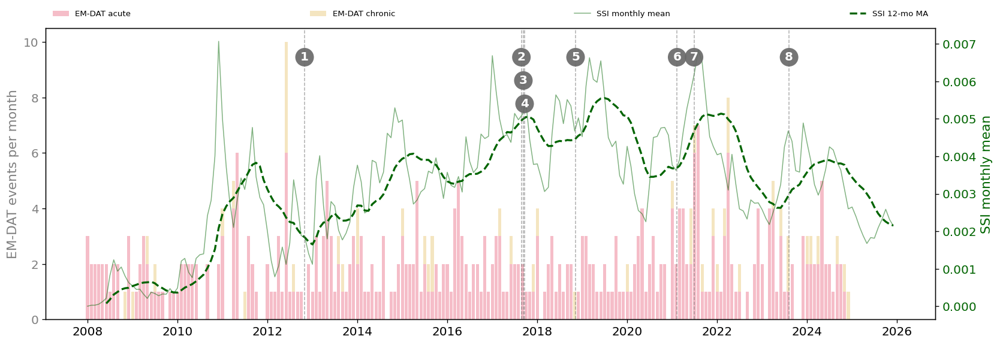

Saved: 09_monthly_SSI.png


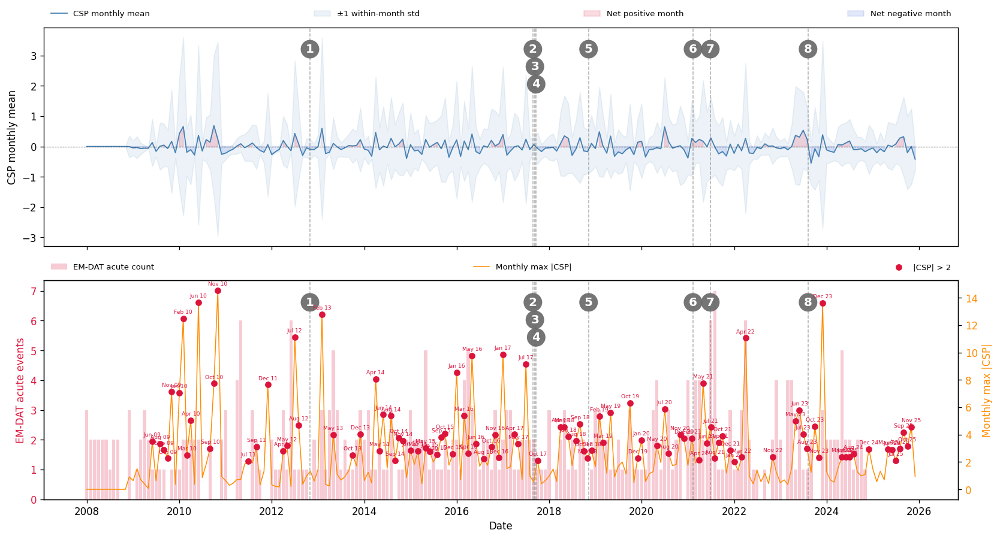

Saved: 10_monthly_CSP.png


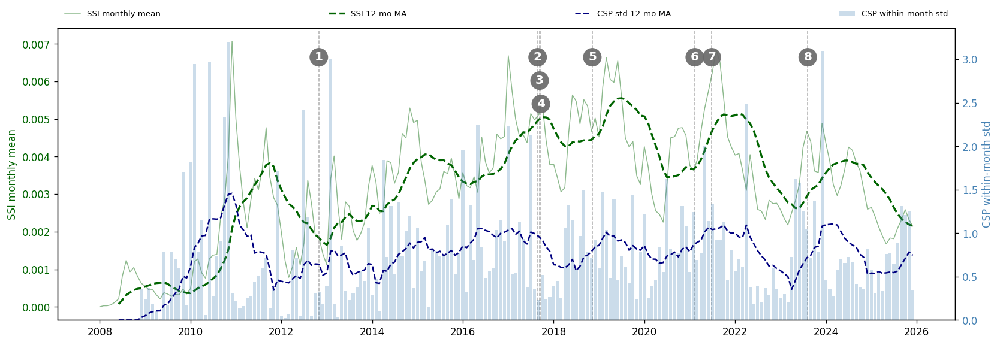

Saved: 11_monthly_chronic_vs_acute.png


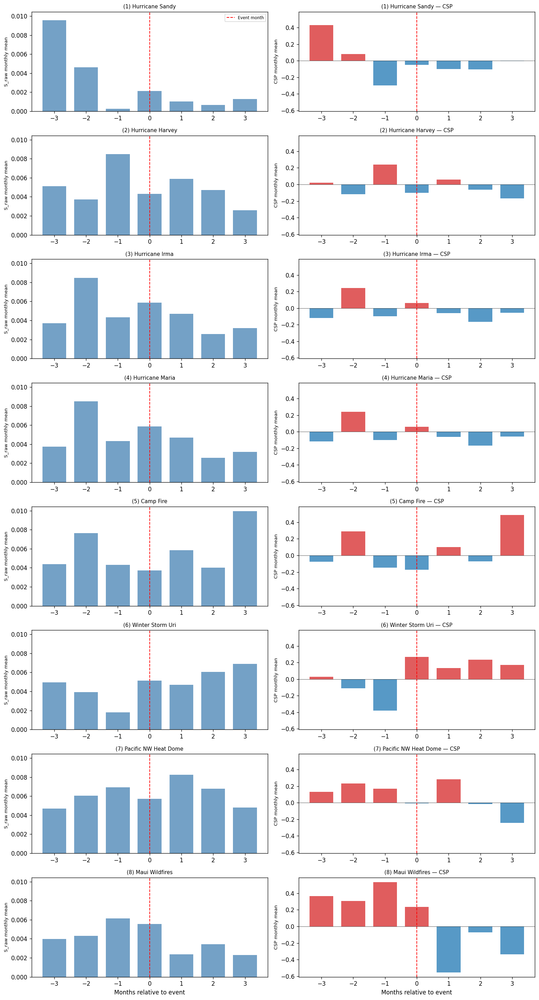

Saved: 12_monthly_event_windows.png


In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

df = df.copy()
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

emdat_us = emdat_us.copy()
emdat_us["event_date"] = pd.to_datetime(emdat_us["event_date"])

WINDOW_MONTHS = 3

EMDAT_EVENTS = [
    ("2012-10-29", "Hurricane Sandy",      "acute"),
    ("2017-08-25", "Hurricane Harvey",     "acute"),
    ("2017-09-10", "Hurricane Irma",       "acute"),
    ("2017-09-20", "Hurricane Maria",      "acute"),
    ("2018-11-08", "Camp Fire",            "acute"),
    ("2021-02-10", "Winter Storm Uri",     "acute"),
    ("2021-06-27", "Pacific NW Heat Dome", "acute"),
    ("2023-08-08", "Maui Wildfires",       "acute"),
]

#  Shared event numbering 
EMDAT_LABELS = {
    "Hurricane Sandy":      1,
    "Hurricane Harvey":     2,
    "Hurricane Irma":       3,
    "Hurricane Maria":      4,
    "Camp Fire":            5,
    "Winter Storm Uri":     6,
    "Pacific NW Heat Dome": 7,
    "Maui Wildfires":       8,
}

def add_numbered_vlines_top(ax, events=EMDAT_EVENTS, fontsize=12):
    """Dashed vline + big numbered circle near the top of the axes. The
    tight 2017 cluster (2=Harvey, 3=Irma, 4=Maria) is stacked with a
    step so the circles don't overlap each other."""
    ax.figure.canvas.draw()
    ylim  = ax.get_ylim()
    yspan = ylim[1] - ylim[0]
    TIER   = {1: 0, 2: 0, 3: 1, 4: 2, 5: 0, 6: 0, 7: 0, 8: 0}
    base_y = ylim[0] + 0.90 * yspan
    step   = 0.08 * yspan
    for edate_str, label, _ in events:
        ts   = pd.Timestamp(edate_str)
        num  = EMDAT_LABELS[label]
        ytop = base_y - TIER[num] * step
        ax.axvline(ts, color="dimgrey", lw=0.9, ls="--", alpha=0.55, ymin=0, zorder=2)
        ax.annotate(
            str(num),
            xy=(ts, ytop), xytext=(ts, ytop),
            ha="center", va="center",
            fontsize=fontsize, fontweight="bold", color="white",
            bbox=dict(boxstyle="circle,pad=0.3", fc="dimgrey", ec="none", alpha=0.92),
            zorder=5,
        )

def band_legend_twin(ax1, ax2, ncol, fontsize=8):
    """Legend as a horizontal band just ABOVE the axes, combining both
    twin-axis handles, so it never overlaps the numbered circles."""
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc="lower left", bbox_to_anchor=(0, 1.01, 1, 0.2),
               mode="expand", ncol=ncol, fontsize=fontsize, frameon=False)

def fmt_years(ax, every=2):
    ax.xaxis.set_major_locator(mdates.YearLocator(every))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

#  Monthly aggregation 
monthly = (df
    .assign(month=lambda d: d["date"].dt.to_period("M").dt.to_timestamp())
    .groupby("month")
    .agg(
        SSI_mean    = ("SSI",         "mean"),
        CSP_mean    = ("CSP",         "mean"),
        CSP_max_abs = ("CSP",         lambda x: x.abs().max()),
        CSP_std     = ("CSP",         "std"),
        S_raw_mean  = ("S_daily_raw", "mean"),
        S_raw_sum   = ("S_daily_raw", "sum"),
    )
    .reset_index()
    .rename(columns={"month": "date"}))

emdat_m = (emdat_us
    .assign(date=lambda d: d["event_date"].dt.to_period("M").dt.to_timestamp())
    .groupby(["date", "etype"]).size()
    .unstack(fill_value=0)
    .reindex(columns=["acute", "chronic"], fill_value=0)
    .reset_index())

monthly = monthly.merge(emdat_m, on="date", how="left").fillna(0)
monthly["SSI_12ma"]     = monthly["SSI_mean"].rolling(12, min_periods=6).mean()
monthly["CSP_std_12ma"] = monthly["CSP_std"].rolling(12, min_periods=6).mean()


# Figure 9 — Monthly SSI and EM-DAT stacked bars and 12-month MA

fig, ax1 = plt.subplots(figsize=(14, 4.9))
ax2 = ax1.twinx()

ax1.bar(monthly["date"], monthly["acute"],
        width=25, color="crimson",   alpha=0.28, label="EM-DAT acute")
ax1.bar(monthly["date"], monthly["chronic"],
        width=25, bottom=monthly["acute"],
        color="goldenrod", alpha=0.28, label="EM-DAT chronic")
ax2.plot(monthly["date"], monthly["SSI_mean"],
         color="darkgreen", lw=0.9, alpha=0.50, label="SSI monthly mean")
ax2.plot(monthly["date"], monthly["SSI_12ma"],
         color="darkgreen", lw=2.0, ls="--", label="SSI 12-mo MA")

ax1.set_ylabel("EM-DAT events per month", color="grey", fontsize=13)
ax2.set_ylabel("SSI monthly mean",        color="darkgreen", fontsize=13)
ax1.tick_params(axis="y", labelcolor="grey", labelsize=12)
ax2.tick_params(axis="y", labelcolor="darkgreen", labelsize=12)
ax1.tick_params(axis="x", labelsize=12)
fmt_years(ax1)
add_numbered_vlines_top(ax2)
band_legend_twin(ax1, ax2, ncol=4)
fig.tight_layout()
fig.savefig(figdir / "09_monthly_SSI.png", dpi=180, bbox_inches="tight")
plt.show()
print("Saved: 09_monthly_SSI.png")


# Figure 10 — Monthly CSP mean ± std (top) and max CSP vs EM-DAT 

fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(14, 7.6), sharex=True)

ax_top.plot(monthly["date"], monthly["CSP_mean"],
            color="steelblue", lw=1.1, label="CSP monthly mean")
ax_top.fill_between(monthly["date"],
                    monthly["CSP_mean"] - monthly["CSP_std"],
                    monthly["CSP_mean"] + monthly["CSP_std"],
                    color="steelblue", alpha=0.10, label="±1 within-month std")
ax_top.axhline(0, color="black", lw=0.5, ls="--")
ax_top.fill_between(monthly["date"], monthly["CSP_mean"], 0,
                    where=monthly["CSP_mean"] > 0,
                    color="crimson",   alpha=0.15, label="Net positive month")
ax_top.fill_between(monthly["date"], monthly["CSP_mean"], 0,
                    where=monthly["CSP_mean"] < 0,
                    color="royalblue", alpha=0.15, label="Net negative month")
ax_top.set_ylabel("CSP monthly mean")
add_numbered_vlines_top(ax_top)
h, l = ax_top.get_legend_handles_labels()
ax_top.legend(h, l, loc="lower left", bbox_to_anchor=(0, 1.01, 1, 0.2),
              mode="expand", ncol=4, fontsize=8, frameon=False)

ax_b2 = ax_bot.twinx()
ax_bot.bar(monthly["date"], monthly["acute"],
           width=25, color="crimson", alpha=0.22, label="EM-DAT acute count")
ax_b2.plot(monthly["date"], monthly["CSP_max_abs"],
           color="darkorange", lw=0.9, label="Monthly max |CSP|")

big = monthly[monthly["CSP_max_abs"] > 2.0]
ax_b2.scatter(big["date"], big["CSP_max_abs"],
              color="crimson", s=30, zorder=5, label="|CSP| > 2")
for _, r in big.iterrows():
    ax_b2.annotate(r["date"].strftime("%b %y"),
                   xy=(r["date"], r["CSP_max_abs"]),
                   xytext=(0, 5), textcoords="offset points",
                   fontsize=5.5, ha="center", color="crimson")

ax_bot.set_ylabel("EM-DAT acute events",  color="crimson")
ax_b2.set_ylabel("Monthly max |CSP|",     color="darkorange")
ax_bot.tick_params(axis="y", labelcolor="crimson")
ax_b2.tick_params(axis="y", labelcolor="darkorange")
ax_bot.set_xlabel("Date")
fmt_years(ax_bot)
add_numbered_vlines_top(ax_bot)
band_legend_twin(ax_bot, ax_b2, ncol=3)

fig.tight_layout()
fig.savefig(figdir / "10_monthly_CSP.png", dpi=180, bbox_inches="tight")
plt.show()
print("Saved: 10_monthly_CSP.png")

# Figure 11 — Chronic vs acute: SSI secular trend vs flat CSP volatility
fig, ax1 = plt.subplots(figsize=(14, 4.9))
ax2 = ax1.twinx()

ax1.plot(monthly["date"], monthly["SSI_mean"],
         color="darkgreen", lw=0.9, alpha=0.45, label="SSI monthly mean")
ax1.plot(monthly["date"], monthly["SSI_12ma"],
         color="darkgreen", lw=2.0, ls="--", label="SSI 12-mo MA")
ax2.bar(monthly["date"], monthly["CSP_std"],
        width=25, color="steelblue", alpha=0.28, label="CSP within-month std")
ax2.plot(monthly["date"], monthly["CSP_std_12ma"],
         color="navy", lw=1.5, ls="--", label="CSP std 12-mo MA")

ax1.set_ylabel("SSI monthly mean",     color="darkgreen")
ax2.set_ylabel("CSP within-month std", color="steelblue")
ax1.tick_params(axis="y", labelcolor="darkgreen")
ax2.tick_params(axis="y", labelcolor="steelblue")
fmt_years(ax1)
add_numbered_vlines_top(ax1)
band_legend_twin(ax1, ax2, ncol=4)
fig.tight_layout()
fig.savefig(figdir / "11_monthly_chronic_vs_acute.png", dpi=180, bbox_inches="tight")
plt.show()
print("Saved: 11_monthly_chronic_vs_acute.png")


# Figure 12 — Event-window bars ±WINDOW_MONTHS months

fig, axes = plt.subplots(len(EMDAT_EVENTS), 2,
                         figsize=(13, 3 * len(EMDAT_EVENTS)),
                         sharey="col")
if len(EMDAT_EVENTS) == 1:
    axes = axes.reshape(1, -1)

for row_i, (edate_str, label, etype) in enumerate(EMDAT_EVENTS):
    edate     = pd.Timestamp(edate_str)
    event_mon = edate.to_period("M").to_timestamp()
    lo        = event_mon - pd.DateOffset(months=WINDOW_MONTHS)
    hi        = event_mon + pd.DateOffset(months=WINDOW_MONTHS)
    sub       = monthly[(monthly["date"] >= lo) & (monthly["date"] <= hi)].copy()
    if sub.empty:
        continue
    sub["rel_month"] = ((sub["date"].dt.year  - event_mon.year) * 12 +
                        (sub["date"].dt.month - event_mon.month))

    ax_raw = axes[row_i, 0]
    ax_csp = axes[row_i, 1]

    ax_raw.bar(sub["rel_month"], sub["S_raw_mean"],
               color="steelblue", alpha=0.75, width=0.75)
    ax_raw.axvline(0, color="red", ls="--", lw=1.2, label="Event month")
    ax_raw.set_ylabel("S_raw monthly mean", fontsize=8)
    ax_raw.set_title(f"({EMDAT_LABELS[label]}) {label}", fontsize=9)
    ax_raw.set_xticks(range(-WINDOW_MONTHS, WINDOW_MONTHS + 1))
    if row_i == 0:
        ax_raw.legend(fontsize=7)

    colors = ["C3" if v > 0 else "C0" for v in sub["CSP_mean"]]
    ax_csp.bar(sub["rel_month"], sub["CSP_mean"],
               color=colors, alpha=0.75, width=0.75)
    ax_csp.axvline(0, color="red", ls="--", lw=1.2)
    ax_csp.axhline(0, color="k",   lw=0.4)
    ax_csp.set_ylabel("CSP monthly mean", fontsize=8)
    ax_csp.set_title(f"({EMDAT_LABELS[label]}) {label} — CSP", fontsize=9)
    ax_csp.set_xticks(range(-WINDOW_MONTHS, WINDOW_MONTHS + 1))

axes[-1, 0].set_xlabel("Months relative to event")
axes[-1, 1].set_xlabel("Months relative to event")
fig.tight_layout()
fig.savefig(figdir / "12_monthly_event_windows.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: 12_monthly_event_windows.png")

## Improving Existing Visuals

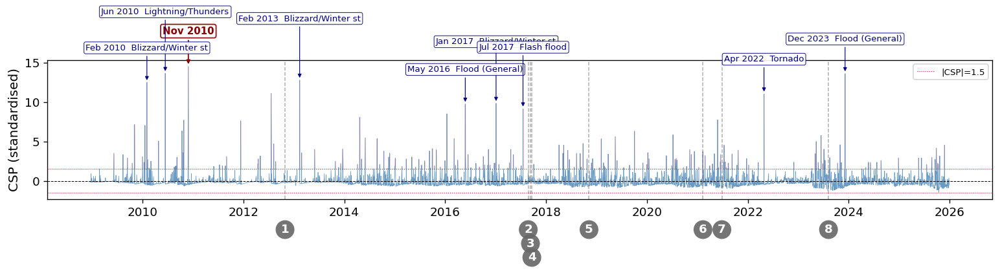

In [43]:
import matplotlib.transforms as transforms

def add_numbered_vlines_bottom(ax, events=KEY_EVENTS, fontsize=11,
                                y_frac=-0.22, row_gap=0.10):
    """Dashed vline spanning the full axes height + numbered circle sitting
    below the x-axis YEAR tick labels (not overlapping them). Uses a blended
    transform (data x, axes-fraction y). The tight 2017 cluster
    (2=Harvey, 3=Irma, 4=Maria) is staggered onto separate rows below that
    so the circles don't overlap each other either."""
    trans = transforms.blended_transform_factory(ax.transData, ax.transAxes)
    TIER = {1: 0, 2: 0, 3: 1, 4: 2, 5: 0, 6: 0, 7: 0, 8: 0}
    for edate_str, label, _ in events:
        ts   = pd.Timestamp(edate_str)
        num  = EMDAT_LABELS[label]
        yrow = y_frac - TIER[num] * row_gap
        ax.axvline(ts, color="dimgrey", lw=0.9, ls="--", alpha=0.55,
                    ymin=0, ymax=1, zorder=2)
        ax.annotate(
            str(num),
            xy=(ts, yrow), xycoords=trans,
            ha="center", va="center",
            fontsize=fontsize, fontweight="bold", color="white",
            bbox=dict(boxstyle="circle,pad=0.3", fc="dimgrey", ec="none", alpha=0.92),
            annotation_clip=False, clip_on=False, zorder=5,
        )

#  Plot 2: Daily CSP with top-10 labelled and numbered event markers 
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(df["date"], df["CSP"], color="steelblue", lw=0.45, alpha=0.8)
ax.axhline(0,    color="black",   lw=0.6, ls="--")
ax.axhline( 1.5, color="crimson", lw=0.7, ls=":", label="|CSP|=1.5")
ax.axhline(-1.5, color="crimson", lw=0.7, ls=":")
ax.fill_between(df["date"], df["CSP"],  1.5, where=df["CSP"] >  1.5,
                color="crimson",   alpha=0.22)
ax.fill_between(df["date"], df["CSP"], -1.5, where=df["CSP"] < -1.5,
                color="royalblue", alpha=0.22)

top10 = df.dropna(subset=["CSP"]).nlargest(10, "CSP")

for i, (_, r) in enumerate(top10.iterrows()):
    is_top = (i == 0)

    if is_top:
        text = "Nov 2010"       
    else:
        nearby = emdat_us[
            (emdat_us["event_date"] >= r["date"] - pd.Timedelta(days=3)) &
            (emdat_us["event_date"] <= r["date"] + pd.Timedelta(days=3))
        ]
        if len(nearby) == 0:     
            continue
        lbl = nearby["Disaster Subtype"].iloc[0][:18]
        text = f"{r['date'].strftime('%b %Y')}  {lbl}"

    dy = 30 if i % 2 == 0 else 55  
    ax.annotate(
        text,
        xy=(r["date"], r["CSP"]),
        xytext=(0, dy),
        textcoords="offset points",
        fontsize=9 if is_top else 8,
        fontweight="bold" if is_top else "normal",
        ha="center", color="darkred" if is_top else "navy",
        bbox=dict(boxstyle="round,pad=0.2", fc="white",
                   ec="darkred" if is_top else "navy",
                   lw=1.1 if is_top else 0.6, alpha=0.9),
        arrowprops=dict(arrowstyle="-|>", color="darkred" if is_top else "navy",
                         lw=1.1 if is_top else 0.7, mutation_scale=7),
    )

ax.legend(fontsize=8, loc="upper right")
ax.set_ylabel("CSP (standardised)", fontsize=12)
ax.tick_params(axis="both", labelsize=11)
fmt_years(ax)
add_numbered_vlines_bottom(ax)

fig.tight_layout()
fig.subplots_adjust(bottom=0.34)  
fig.savefig(figdir / "02_daily_CSP.png", dpi=170, bbox_inches="tight")
plt.show()